# COS 711 Assignment 2 · Segmenting solar filaments with deep learning

Kaggle: [Solar Filament Segmentation Challenge 2026](https://www.kaggle.com/competitions/filament-segmentation-2026),
ranked by **Panoptic Quality (PQ)**. Data: MAGFiLO (GONG H-alpha, 2048×2048, expert polygons).

## Group members and responsibilities

| Member | Student no. | Responsibility (marking category) |
|---|---|---|
| Malaika Kamangu | u23618583 | Format · Data preparation · Experimental setup & methodology |
| Stefan Muller | u22498622 | *Segmentation results* or *Segmentation enhancement* — fill in |
| Karabo | u23543087 | *Segmentation results* or *Segmentation enhancement* — fill in |

## Where each marking category is covered

| Rubric category | Marks | Notebook sections |
|---|---|---|
| Data preparation | 10 | 1 (EDA, preprocessing, augmentation, grouped split) |
| Experimental setup & methodology | 20 | 0.2–0.3, 2 (PQ, model, losses, training, ablations, tuning, 5-fold final model) |
| Segmentation results | 30 | 3 |
| Segmentation enhancement | 30 | 4 |
| Conclusions | 5 | 5 |
| Format | 5 | slides + video (outside this notebook) |

Sections follow the order of the presentation (spec §4): data → methodology → results →
enhancement → conclusions → bibliography. This notebook is the team's single source of code: every
module of the `filaments` package is written by a `%%writefile` cell in the section it belongs to.

# 0. Setup & Imports

**How to use this notebook.** It runs in two places with the same code:

* **Google Colab** (Runtime → Change runtime type → **T4 GPU**): downloads the competition data with
  your Kaggle token and keeps the cache and runs on Google Drive.
* **Locally** (from the repository root or `notebooks/`): uses `data/MAGFiLO_1.0_Kaggle_2026` and
  `runs/`.

Two modes: `TRAIN = False` (default) analyses the team's trained runs in `RUNS_DIR` without a GPU;
`TRAIN = True` retrains (≈ 25 min per run on a T4). All outputs shown were produced by this notebook.

## 0.1 Imports

In [1]:
import os, sys, json, time, random
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q segmentation-models-pytorch==0.5.0 pycocotools kagglehub
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2, torch
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

torch 2.14.1 | GPU: none


## 0.2 Config / Constants

Global configuration. These are the defaults of `python -m filaments.train` and the protocol used
for every methodology experiment (one change per experiment, section 2.6). `scale = 0.5` means
the 2048² disk is seen by the network at 1024², chosen because the median filament is ≈ 8 px wide
(section 1.2): at 512² a third of filaments would be ≤ 2 px wide.

In [2]:
CONFIG = dict(
    arch="unet", encoder="resnet34", weights="imagenet",   # model
    scale=0.5, crop=512, pos_frac=0.7,                     # data: resolution, crop size, filament-centred crops
    label_mode="separate",                                 # each annotator's set is its own sample
    loss="bce:1,dice:1",                                   # imbalance-robust combination
    epochs=20, samples_per_epoch=1000, batch_size=8,       # methodology budget (20 x 1000 crops)
    lr=3e-4, weight_decay=1e-4, warmup_epochs=1.0,         # AdamW + warm-up + cosine decay
    threshold=0.5, min_area=100,                           # post-processing during validation
    fold=0, seed=0,
)
TRAIN = False          # True: retrain runs here; False: analyse the team's trained runs in RUNS_DIR
def train_cmd(name, **overrides):
    c = CONFIG | overrides
    args = [f"--{k.replace('_', '-')} {v}" for k, v in c.items()]
    return f"python -m filaments.train --name {name} --workers 2 --save-probs --val-every 2 " + " ".join(args)
print(train_cmd("example"))

python -m filaments.train --name example --workers 2 --save-probs --val-every 2 --arch unet --encoder resnet34 --weights imagenet --scale 0.5 --crop 512 --pos-frac 0.7 --label-mode separate --loss bce:1,dice:1 --epochs 20 --samples-per-epoch 1000 --batch-size 8 --lr 0.0003 --weight-decay 0.0001 --warmup-epochs 1.0 --threshold 0.5 --min-area 100 --fold 0 --seed 0


## 0.3 Reproducibility (seeds)

Python, NumPy and PyTorch are seeded from `--seed` (`filaments.train.seed_everything`). Each
DataLoader worker draws crops from its own RNG derived from the seed, sample index and worker seed,
so crops differ across workers and epochs but a run is repeatable. Run-to-run variation is measured
explicitly by repeating the baseline with seeds 0, 1, 2 (section 2.6); the folds are deterministic
(seed 0, section 1.5).

In [3]:
def seed_everything(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
seed_everything(CONFIG["seed"])

## 0.4 Device setup, data access & paths

* **Colab, Kaggle data**: add your Kaggle API token in Colab 🔑 *Secrets* as `KAGGLE_API_TOKEN` (the
  `KGAT_...` value) and enable notebook access. You must have joined the competition on Kaggle.
* **Colab, Google Drive** keeps the cache and training runs across sessions (`MyDrive/COS711_A2/`).
* **RUNS_DIR**: trained runs (copy the team's `runs/` folder there to analyse results without retraining).

In [4]:
if IN_COLAB:
    from google.colab import userdata, drive
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    import kagglehub
    path = kagglehub.competition_download("filament-segmentation-2026")
    os.environ["FILAMENT_DATA"] = os.path.join(path, "MAGFiLO_1.0_Kaggle_2026")
    drive.mount("/content/drive")
    WORK = "/content/drive/MyDrive/COS711_A2"
else:   # local: repository root (data in data/MAGFiLO_1.0_Kaggle_2026)
    WORK = str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
for d in ["src/filaments", "tools", "data", "runs", "submissions", "reports/figures", "reports/eda", "reports/methodology"]:
    os.makedirs(f"{WORK}/{d}", exist_ok=True)
os.chdir(WORK)
sys.path.insert(0, f"{WORK}/src")
os.environ["PYTHONPATH"] = f"{WORK}/src"
# Python caches each folder's file list and refreshes it only when the folder's mtime changes; Google
# Drive does not reliably update it, so modules written by later %%writefile cells would stay invisible.
import importlib
get_ipython().events.register("pre_run_cell", lambda info: importlib.invalidate_caches())
RUNS_DIR = f"{WORK}/runs"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("work dir:", WORK, "| device:", DEVICE)

work dir: /Users/malaika/School/711/Assignment 2 | device: mps


# 1. Dataset Preparation
## 1.1 Data loading & inspection

Annotations are COCO-style polygons. Image ids look like `010401-20160920230134Lh`
(annotator batch + observation `YYYYMMDDHHMMSS` + GONG site). One observation can have up to three
independent **annotation sets**; Kaggle suggests treating them as different images, and every
split below is made over *observations* so that sets of one image never straddle train/validation.

In [5]:
%%writefile src/filaments/__init__.py
"""Solar filament segmentation package."""

Overwriting src/filaments/__init__.py


In [6]:
%%writefile src/filaments/data.py
"""MAGFiLO (Kaggle 2026) loading and leakage-safe train/validation splitting.

Naming:
  observation  = image file stem, e.g. 20160920230134Lh  (YYYYMMDDHHMMSS + 2-letter GONG site)
  annotation set = COCO image entry, e.g. 010401-20160920230134Lh (annotator batch + observation)
One observation can carry several independent annotation sets. Splits are always made over
observations (never annotation sets), grouped further by time so near-duplicate days don't leak.
"""
from __future__ import annotations

import json
import os
from dataclasses import dataclass
from datetime import datetime
from pathlib import Path

import cv2
import numpy as np

from .rle import polygon_to_mask

PROJECT_ROOT = Path(__file__).resolve().parents[2]
# On Kaggle: FILAMENT_DATA=/kaggle/input/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026
DATA_ROOT = Path(os.environ.get("FILAMENT_DATA", PROJECT_ROOT / "data" / "MAGFiLO_1.0_Kaggle_2026"))
TRAIN_JSON = DATA_ROOT / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
TRAIN_IMAGES = DATA_ROOT / "train" / "train_images"
TEST_IMAGES = DATA_ROOT / "test" / "test_images"

SITES = {"Bh": "Big Bear", "Mh": "Mauna Loa", "Lh": "Learmonth", "Uh": "Udaipur",
         "Th": "El Teide", "Ch": "Cerro Tololo"}


def parse_observation(stem: str) -> tuple[datetime, str]:
    """'20160920230134Lh' -> (datetime, 'Lh')."""
    return datetime.strptime(stem[:14], "%Y%m%d%H%M%S"), stem[14:16]


@dataclass
class AnnotationSet:
    set_id: str            # COCO image id, e.g. 010401-20160920230134Lh
    observation: str       # 20160920230134Lh
    file_name: str
    height: int
    width: int
    polygons: list[list[float]]
    categories: list[int]

    @property
    def time(self) -> datetime:
        return parse_observation(self.observation)[0]

    @property
    def site(self) -> str:
        return parse_observation(self.observation)[1]

    def instance_masks(self) -> list[np.ndarray]:
        return [polygon_to_mask(p, self.height, self.width) for p in self.polygons]

    def label_map(self) -> np.ndarray:
        """Instance label map; on overlaps the later polygon wins."""
        labels = np.zeros((self.height, self.width), dtype=np.int32)
        for k, m in enumerate(self.instance_masks(), start=1):
            labels[m] = k
        return labels


def load_annotation_sets(path: Path = TRAIN_JSON) -> list[AnnotationSet]:
    coco = json.loads(Path(path).read_text())
    by_image: dict = {img["id"]: img for img in coco["images"]}
    anns: dict = {k: [] for k in by_image}
    for a in coco["annotations"]:
        # The data page lists annotation.image_id as int but image.id as str; normalise both.
        key = a["image_id"] if a["image_id"] in by_image else str(a["image_id"])
        anns.setdefault(key, []).append(a)
    sets = []
    for img_id, img in by_image.items():
        stem = Path(img["file_name"]).stem
        sets.append(AnnotationSet(
            set_id=str(img_id), observation=stem, file_name=img["file_name"],
            height=img["height"], width=img["width"],
            polygons=[a["segmentation"][0] for a in anns.get(img_id, [])],
            categories=[a["category_id"] for a in anns.get(img_id, [])],
        ))
    return sets


def load_image(path: Path | str) -> np.ndarray:
    """Grayscale uint8 HxW (the JPEGs are single-channel; never treat them as RGB)."""
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(path)
    return img


def image_path(observation: str) -> Path:
    for root in (TRAIN_IMAGES, TEST_IMAGES):
        p = root / f"{observation}.jpeg"
        if p.exists():
            return p
    raise FileNotFoundError(observation)


def _circle_lsq(x: np.ndarray, y: np.ndarray) -> tuple[float, float, float]:
    """Algebraic (Kasa) least-squares circle fit."""
    A = np.c_[2 * x, 2 * y, np.ones_like(x)]
    (cx, cy, c), *_ = np.linalg.lstsq(A, x**2 + y**2, rcond=None)
    return cx, cy, np.sqrt(c + cx**2 + cy**2)


# GONG H-alpha frames are pre-centred and scaled: ~80% of images fit to this disk within a few px.
NOMINAL_DISK = (1023.0, 1024.0, 903.5)


def fit_disk(img: np.ndarray, n_rays: int = 360, search: float = 0.06) -> tuple[float, float, float]:
    """Solar disk (cx, cy, r) in pixels.

    The JPEGs contain a grey off-limb halo (with prominences) around the disk whose outer edge is
    often a stronger edge than the limb itself, and the halo is not always concentric. So: start
    from the nominal GONG disk, find the steepest intensity drop along radial rays within
    +-`search` of the nominal radius (the limb), and fit a circle to those edge points with outlier
    rejection (prominences / dark filaments at the limb produce stray edges)."""
    cx, cy, r = NOMINAL_DISK
    smooth = cv2.GaussianBlur(img.astype(np.float32), (0, 0), 2)
    theta = np.linspace(0, 2 * np.pi, n_rays, endpoint=False)
    for _ in range(2):  # second pass re-samples rays from the refined centre
        radii = np.arange((1 - search) * r, (1 + search) * r)
        xs = cx + np.outer(np.cos(theta), radii)
        ys = cy + np.outer(np.sin(theta), radii)
        prof = cv2.remap(smooth, xs.astype(np.float32), ys.astype(np.float32), cv2.INTER_LINEAR,
                         borderMode=cv2.BORDER_CONSTANT, borderValue=0)
        drop = np.argmin(np.diff(prof, axis=1), axis=1)
        ex, ey = xs[np.arange(n_rays), drop], ys[np.arange(n_rays), drop]
        keep = np.ones(n_rays, bool)
        for _ in range(3):
            cx, cy, r = _circle_lsq(ex[keep], ey[keep])
            resid = np.abs(np.hypot(ex - cx, ey - cy) - r)
            keep = resid < max(3 * 1.4826 * np.median(resid[keep]), 2.0)
    return float(cx), float(cy), float(r)


def time_group(observation: str, days: int = 27) -> int:
    """Bucket observations into blocks of `days` (default ~one solar rotation) so filaments seen
    on consecutive days, which are near-duplicates, land in the same fold."""
    t, _ = parse_observation(observation)
    return (t - datetime(2000, 1, 1)).days // days


def make_folds(observations: list[str], n_folds: int = 5, days: int = 27, seed: int = 0) -> dict[str, int]:
    """Assign each observation to a fold. Groups = time blocks; blocks are distributed greedily
    (largest first) to balance fold sizes. Returns {observation: fold}."""
    rng = np.random.default_rng(seed)
    groups: dict[int, list[str]] = {}
    for obs in sorted(set(observations)):
        groups.setdefault(time_group(obs, days), []).append(obs)
    keys = list(groups)
    rng.shuffle(keys)
    keys.sort(key=lambda k: -len(groups[k]))
    sizes = np.zeros(n_folds, dtype=int)
    fold_of: dict[str, int] = {}
    for k in keys:
        f = int(sizes.argmin())
        sizes[f] += len(groups[k])
        for obs in groups[k]:
            fold_of[obs] = f
    return fold_of

Overwriting src/filaments/data.py


In [7]:
%%writefile src/filaments/rle.py
"""COCO RLE helpers and submission writing.

Kaggle expects one row per predicted filament: `filament_id` (<image stem>_<k>) and
`segmentation_rle` (COCO compressed RLE counts only; size is fixed at 2048x2048).
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from pycocotools import mask as mask_utils

IMAGE_SIZE = 2048


def encode(mask: np.ndarray) -> str:
    """Binary HxW mask -> COCO compressed RLE counts string."""
    rle = mask_utils.encode(np.asfortranarray(mask.astype(np.uint8)))
    return rle["counts"].decode("ascii")


def decode(counts: str, size: int = IMAGE_SIZE) -> np.ndarray:
    """COCO compressed RLE counts string -> boolean HxW mask."""
    return mask_utils.decode({"size": [size, size], "counts": counts.encode("ascii")}).astype(bool)


def polygon_to_mask(polygon: list[float], height: int, width: int) -> np.ndarray:
    """Flat [x0, y0, x1, y1, ...] polygon -> boolean mask (same rasterisation as pycocotools)."""
    rles = mask_utils.frPyObjects([polygon], height, width)
    return mask_utils.decode(mask_utils.merge(rles)).astype(bool)


def label_map_to_rows(image_stem: str, labels: np.ndarray) -> list[dict]:
    """Instance label map (0 = background) -> submission rows for one image."""
    rows = []
    for k, lab in enumerate(np.unique(labels[labels > 0]), start=1):
        rows.append({"filament_id": f"{image_stem}_{k}", "segmentation_rle": encode(labels == lab)})
    return rows


def write_submission(rows: list[dict], path: str) -> pd.DataFrame:
    df = pd.DataFrame(rows, columns=["filament_id", "segmentation_rle"])
    # Kaggle forbids quotes around the RLE strings; RLE counts never contain commas.
    df.to_csv(path, index=False, quoting=3)  # csv.QUOTE_NONE
    return df


def read_submission(path: str) -> dict[str, list[np.ndarray]]:
    """Submission CSV -> {image_stem: [instance masks]} (for sanity-checking before upload)."""
    df = pd.read_csv(path, quoting=3, dtype=str)
    out: dict[str, list[np.ndarray]] = {}
    for fid, counts in zip(df.filament_id, df.segmentation_rle):
        out.setdefault(fid.rsplit("_", 1)[0], []).append(decode(counts))
    return out

Overwriting src/filaments/rle.py


In [8]:
%%writefile src/filaments/metrics.py
"""Local evaluation: Panoptic Quality (Kirillov et al., 2019), Dice, and fragmentation stats.

PQ for one class:
    PQ = sum_{(g,p) in TP} IoU(g,p) / (|TP| + 0.5|FP| + 0.5|FN|)
where a (gt, pred) pair is a TP iff IoU > 0.5. With IoU > 0.5 every gt can match at most
one pred and vice versa, so matching is unique and needs no Hungarian assignment.

Kaggle's exact aggregation (dataset-level vs. mean of per-image PQ) is not stated, so both
are reported; check them against the self-evaluation notebook / first LB submission.
"""
from __future__ import annotations

from dataclasses import dataclass, field

import numpy as np

# Minimum IoU for a pred to count as "touching" a gt when counting one-to-many / many-to-one.
FRAG_IOU = 0.05


@dataclass
class ImageStats:
    tp: int = 0
    fp: int = 0
    fn: int = 0
    iou_sum: float = 0.0
    one_to_many: int = 0   # gt instances split across >1 prediction (fragmentation)
    many_to_one: int = 0   # predictions covering >1 gt instance (over-merging)
    matched_ious: list[float] = field(default_factory=list)

    @property
    def pq(self) -> float:
        denom = self.tp + 0.5 * self.fp + 0.5 * self.fn
        return self.iou_sum / denom if denom else float("nan")

    @property
    def sq(self) -> float:
        return self.iou_sum / self.tp if self.tp else 0.0

    @property
    def rq(self) -> float:
        denom = self.tp + 0.5 * self.fp + 0.5 * self.fn
        return self.tp / denom if denom else float("nan")


def _as_masks(x) -> list[np.ndarray]:
    """Accept a label map (HxW int, 0 = bg) or a list/stack of boolean masks."""
    if isinstance(x, np.ndarray) and x.ndim == 2 and not x.dtype == bool:
        return [x == lab for lab in np.unique(x[x > 0])]
    return [np.asarray(m, dtype=bool) for m in x]


def iou_matrix(gts: list[np.ndarray], preds: list[np.ndarray]) -> np.ndarray:
    if not gts or not preds:
        return np.zeros((len(gts), len(preds)))
    g = np.stack(gts).reshape(len(gts), -1).astype(np.float32)
    p = np.stack(preds).reshape(len(preds), -1).astype(np.float32)
    inter = g @ p.T
    union = g.sum(1)[:, None] + p.sum(1)[None, :] - inter
    return np.where(union > 0, inter / np.maximum(union, 1), 0.0)


def stats_from_iou(iou: np.ndarray, n_gt: int, n_pred: int) -> ImageStats:
    """PQ bookkeeping from an (n_gt, n_pred) IoU matrix (lets callers compute IoU however is
    fastest, e.g. pycocotools on RLEs)."""
    s = ImageStats()
    if n_gt and n_pred:
        match = iou > 0.5
        s.tp = int(match.sum())
        s.matched_ious = iou[match].tolist()
        s.iou_sum = float(iou[match].sum())
        s.fn = n_gt - int(match.any(1).sum())
        s.fp = n_pred - int(match.any(0).sum())
        touch = iou > FRAG_IOU
        s.one_to_many = int((touch.sum(1) > 1).sum())
        s.many_to_one = int((touch.sum(0) > 1).sum())
    else:
        s.fn, s.fp = n_gt, n_pred
    return s


def image_stats(gt, pred) -> ImageStats:
    gts, preds = _as_masks(gt), _as_masks(pred)
    return stats_from_iou(iou_matrix(gts, preds), len(gts), len(preds))


def aggregate(stats: list[ImageStats]) -> dict[str, float]:
    tp = sum(s.tp for s in stats)
    fp = sum(s.fp for s in stats)
    fn = sum(s.fn for s in stats)
    iou_sum = sum(s.iou_sum for s in stats)
    denom = tp + 0.5 * fp + 0.5 * fn
    per_image = np.array([s.pq for s in stats], dtype=float)
    return {
        "pq_global": iou_sum / denom if denom else float("nan"),
        "pq_mean_image": float(np.nanmean(per_image)) if np.isfinite(per_image).any() else float("nan"),
        "sq": iou_sum / tp if tp else 0.0,
        "rq": tp / denom if denom else float("nan"),
        "tp": tp, "fp": fp, "fn": fn,
        "one_to_many": sum(s.one_to_many for s in stats),
        "many_to_one": sum(s.many_to_one for s in stats),
    }


def dice(gt_binary: np.ndarray, pred_binary: np.ndarray, eps: float = 1e-7) -> float:
    """Semantic (union-of-instances) Dice for one image."""
    g, p = gt_binary.astype(bool), pred_binary.astype(bool)
    denom = g.sum() + p.sum()
    if denom == 0:
        return 1.0
    return float(2 * (g & p).sum() / (denom + eps))

Overwriting src/filaments/metrics.py


In [9]:
%%writefile src/filaments/analysis.py
"""Dataset analysis (notebook section 1.2: data inventory, image quality, filament geometry, annotator agreement).

Heavy per-image / per-annotation-set work lives here so it can run in a process pool and be
cached to CSV; the notebook only loads tables and plots.
"""
from __future__ import annotations

from concurrent.futures import ProcessPoolExecutor
from itertools import combinations

import cv2
import numpy as np
import pandas as pd
from pycocotools import mask as mask_utils
from skimage.morphology import skeletonize

from .data import AnnotationSet, fit_disk, image_path, load_image, parse_observation
from .metrics import stats_from_iou

N_RADIAL = 20      # radial bins over r/R in [0, 1] for limb-darkening profiles
GAP_CAP = 150      # px; nearest-neighbour gaps beyond this are reported as the cap


# ---------------------------------------------------------------- image quality

def _image_row(observation: str) -> dict:
    img = load_image(image_path(observation))
    cx, cy, r = fit_disk(img)
    yy, xx = np.mgrid[: img.shape[0], : img.shape[1]]
    rho = np.hypot(xx - cx, yy - cy) / r
    disk = rho < 1.0
    inner = rho < 0.9
    f = img.astype(np.float32)

    bins = np.minimum((rho * N_RADIAL).astype(int), N_RADIAL)
    sums = np.bincount(bins[disk], weights=f[disk], minlength=N_RADIAL)[:N_RADIAL]
    counts = np.bincount(bins[disk], minlength=N_RADIAL)[:N_RADIAL]
    profile = sums / np.maximum(counts, 1)

    # Limb-flattened image: divide out the radial profile, then measure what is left at large
    # scales (clouds, haze, gradients) vs. small scales (sharpness / seeing).
    flat = np.ones_like(f)
    flat[disk] = f[disk] / np.maximum(profile[bins[disk]], 1)
    large = cv2.GaussianBlur(flat, (0, 0), 40)
    lap = cv2.Laplacian(f, cv2.CV_32F, ksize=3)

    t, site = parse_observation(observation)
    row = {
        "observation": observation, "site": site, "time": t,
        "cx": cx, "cy": cy, "r": r,
        "median": float(np.median(f[inner])),
        "iqr": float(np.subtract(*np.percentile(f[inner], [75, 25]))),
        "sharpness": float(lap[inner].var()),
        "nonuniformity": float(large[inner].std()),
        "dark_frac": float((flat[inner] < 0.75).mean()),   # fraction of clearly dark disk pixels
    }
    row.update({f"prof_{i:02d}": float(v) for i, v in enumerate(profile)})
    return row


def image_quality_table(observations: list[str], workers: int = 8) -> pd.DataFrame:
    with ProcessPoolExecutor(workers) as ex:
        rows = list(ex.map(_image_row, observations, chunksize=8))
    return pd.DataFrame(rows)


# ---------------------------------------------------------------- filament geometry

def _bbox(m: np.ndarray) -> tuple[int, int, int, int]:
    ys, xs = np.nonzero(m)
    return ys.min(), ys.max() + 1, xs.min(), xs.max() + 1


def _set_rows(args) -> tuple[list[dict], dict]:
    s, disk = args
    cx, cy, r = disk
    masks = s.instance_masks()
    occ = np.zeros((s.height, s.width), np.uint8)
    for m in masks:
        occ += m
    rows = []
    for k, (m, cat) in enumerate(zip(masks, s.categories)):
        if not m.any():
            rows.append({"set_id": s.set_id, "observation": s.observation, "k": k, "area": 0})
            continue
        y0, y1, x0, x1 = _bbox(m)
        Y0, Y1 = max(y0 - GAP_CAP, 0), min(y1 + GAP_CAP, s.height)
        X0, X1 = max(x0 - GAP_CAP, 0), min(x1 + GAP_CAP, s.width)
        mc = m[Y0:Y1, X0:X1]
        others = (occ[Y0:Y1, X0:X1] - mc) > 0
        if others.any():
            dist_to_others = cv2.distanceTransform((~others).astype(np.uint8), cv2.DIST_L2, 5)
            gap = float(min(dist_to_others[mc].min(), GAP_CAP))
        else:
            gap = float(GAP_CAP)

        own = np.pad(m[y0:y1, x0:x1], 1)
        edt = cv2.distanceTransform(own.astype(np.uint8), cv2.DIST_L2, 5)
        skel = skeletonize(own)
        half = edt[skel] if skel.any() else edt[own]
        contour = max(cv2.findContours(own.astype(np.uint8), cv2.RETR_EXTERNAL,
                                       cv2.CHAIN_APPROX_NONE)[0], key=cv2.contourArea)
        hull_area = cv2.contourArea(cv2.convexHull(contour))
        area = int(m.sum())
        ys, xs = np.nonzero(m)
        rows.append({
            "set_id": s.set_id, "observation": s.observation, "site": s.site, "k": k,
            "category": cat, "area": area, "bbox_w": x1 - x0, "bbox_h": y1 - y0,
            "width_median": 2 * float(np.median(half)), "width_max": 2 * float(half.max()),
            "skeleton_len": int(skel.sum()),
            "solidity": area / hull_area if hull_area else 1.0,
            "r_norm": float(np.hypot(xs.mean() - cx, ys.mean() - cy) / r),
            "gap_to_nearest": gap,
            "touches_other": bool(((occ > 1) & m).any()),
        })
    set_row = {
        "set_id": s.set_id, "observation": s.observation, "site": s.site,
        "n_filaments": len(masks),
        "filament_px": int((occ > 0).sum()),
        "overlap_px": int((occ > 1).sum()),
        "disk_px": float(np.pi * r * r),
    }
    return rows, set_row


def filament_tables(sets: list[AnnotationSet], disks: dict[str, tuple[float, float, float]],
                    workers: int = 8) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Per-filament geometry and per-annotation-set summaries."""
    with ProcessPoolExecutor(workers) as ex:
        out = list(ex.map(_set_rows, [(s, disks[s.observation]) for s in sets], chunksize=4))
    fil = pd.DataFrame([r for rows, _ in out for r in rows])
    per_set = pd.DataFrame([sr for _, sr in out])
    per_set["filament_frac"] = per_set.filament_px / per_set.disk_px
    return fil, per_set


# ---------------------------------------------------------------- annotator agreement

def _rles(s: AnnotationSet):
    return [mask_utils.merge(mask_utils.frPyObjects([p], s.height, s.width)) for p in s.polygons]


def agreement_table(sets: list[AnnotationSet]) -> pd.DataFrame:
    """PQ / Dice between every pair of annotation sets of the same observation.
    PQ is symmetric in its arguments, so each unordered pair is scored once."""
    by_obs: dict[str, list[AnnotationSet]] = {}
    for s in sets:
        by_obs.setdefault(s.observation, []).append(s)
    rows = []
    for obs, group in by_obs.items():
        if len(group) < 2:
            continue
        rles = {s.set_id: _rles(s) for s in group}
        for a, b in combinations(group, 2):
            ra, rb = rles[a.set_id], rles[b.set_id]
            # pycocotools.iou(dt, gt) -> (len(dt), len(gt)); we want (gt=a, pred=b).
            iou = np.asarray(mask_utils.iou(rb, ra, [0] * len(ra))).T if ra and rb else np.zeros((len(ra), len(rb)))
            st = stats_from_iou(iou, len(ra), len(rb))
            ua, ub = mask_utils.merge(ra), mask_utils.merge(rb)
            A, B = mask_utils.area(ua), mask_utils.area(ub)
            u_iou = float(mask_utils.iou([ub], [ua], [0])[0][0])
            inter = u_iou * (A + B) / (1 + u_iou)
            rows.append({
                "observation": obs, "site": a.site, "set_a": a.set_id, "set_b": b.set_id,
                "n_a": len(ra), "n_b": len(rb),
                "pq": st.pq, "sq": st.sq, "rq": st.rq,
                "tp": st.tp, "fp": st.fp, "fn": st.fn,
                "one_to_many": st.one_to_many, "many_to_one": st.many_to_one,
                "dice": 2 * inter / (A + B) if A + B else 1.0,
            })
    return pd.DataFrame(rows)


# ---------------------------------------------------------------- drawing

def overlay(img: np.ndarray, masks: list[np.ndarray], colors: list[tuple[int, int, int]],
            thickness: int = 3) -> np.ndarray:
    """RGB image with each instance outlined in its own colour."""
    out = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    for i, m in enumerate(masks):
        cs, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(out, cs, -1, colors[i % len(colors)], thickness)
    return out

Overwriting src/filaments/analysis.py


In [10]:
%%writefile src/filaments/viz.py
"""Shared matplotlib style for report/slide figures (one consistent look across notebooks)."""
from __future__ import annotations

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt

FIG_DIR = Path(__file__).resolve().parents[2] / "reports" / "figures"

SURFACE = "#fcfcfb"
TEXT = "#0b0b0b"
TEXT_2 = "#52514e"
GRID = "#e4e3df"
# Categorical slots in fixed order (validated palette); sites always map to the same slot.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SITE_ORDER = ["Bh", "Ch", "Lh", "Mh", "Th", "Uh"]
SITE_COLOR = dict(zip(SITE_ORDER, SERIES))
SEQ = "#2a78d6"          # single-series / sequential hue
ACCENT = "#eb6834"       # second series (e.g. test vs train)


def setup() -> None:
    mpl.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
        "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
        "axes.edgecolor": GRID, "axes.labelcolor": TEXT_2, "text.color": TEXT,
        "xtick.color": TEXT_2, "ytick.color": TEXT_2,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
        "axes.spines.top": False, "axes.spines.right": False,
        "legend.frameon": False, "lines.linewidth": 2,
        "axes.prop_cycle": mpl.cycler(color=SERIES),
    })


def save(fig, name: str) -> Path:
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path)
    return path


def hex_to_rgb(h: str) -> tuple[int, int, int]:
    return tuple(int(h[i:i + 2], 16) for i in (1, 3, 5))


def no_axes(ax) -> None:
    ax.set_axis_off()
    ax.grid(False)

Overwriting src/filaments/viz.py


In [11]:
from filaments.data import (load_annotation_sets, parse_observation, make_folds, load_image, image_path,
                            fit_disk, TEST_IMAGES, SITES)
from filaments import analysis as A, viz
viz.setup()
EDA = Path("reports/eda")
summary = {}       # key EDA numbers, saved to reports/eda/summary.json at the end of section 1

sets = load_annotation_sets()
train_obs = sorted({s.observation for s in sets})
test_obs = sorted(p.stem for p in TEST_IMAGES.glob("*.jpeg"))
sets_per_obs = pd.Series([s.observation for s in sets]).value_counts()
cats = pd.Series([c for s in sets for c in s.categories]).map({1: "Left", 2: "Right", 3: "Unidentifiable", 4: "Ambiguous"})
summary.update(train_observations=len(train_obs), test_observations=len(test_obs), annotation_sets=len(sets),
               filaments=sum(len(s.polygons) for s in sets),
               sets_per_observation=sets_per_obs.value_counts().sort_index().to_dict(),
               category_counts=cats.value_counts().to_dict())
summary

{'train_observations': 707,
 'test_observations': 180,
 'annotation_sets': 1154,
 'filaments': 8199,
 'sets_per_observation': {1: 411, 2: 145, 3: 151},
 'category_counts': {'Unidentifiable': 3074, 'Right': 2590, 'Left': 2535}}

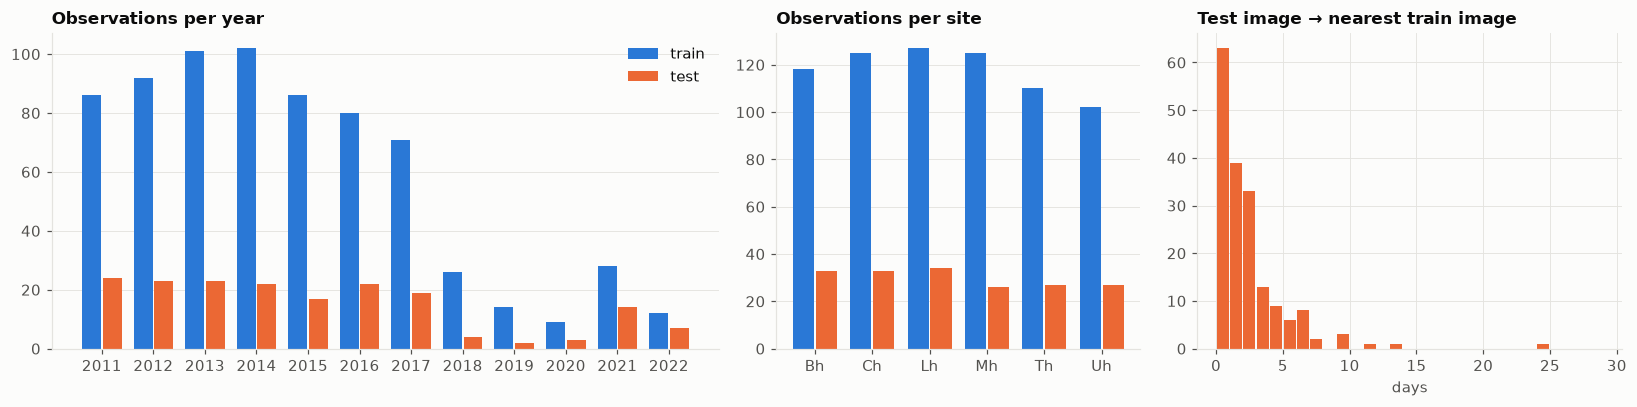

{'median': 36.68055555555556, 'lt_24h': 63, 'lt_7d': 171}

In [12]:
meta = pd.DataFrame([{"observation": o, "split": sp, "site": o[14:16], "year": int(o[:4]),
                      "time": parse_observation(o)[0]}
                     for sp, lst in [("train", train_obs), ("test", test_obs)] for o in lst])
t_train = np.array([t.timestamp() for t in meta.query("split == 'train'").time])
gap_h = np.array([np.abs(t_train - t.timestamp()).min() / 3600 for t in meta.query("split == 'test'").time])
summary["test_to_nearest_train_hours"] = {"median": float(np.median(gap_h)), "lt_24h": int((gap_h < 24).sum()),
                                          "lt_7d": int((gap_h < 168).sum())}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [2.2, 1.2, 1.4]})
for ax, key in zip(axes[:2], ["year", "site"]):
    tab = meta.pivot_table(index=key, columns="split", values="observation", aggfunc="count").fillna(0)
    x = np.arange(len(tab)); w = 0.4
    ax.bar(x - w/2, tab["train"], w * 0.92, color=viz.SEQ, label="train")
    ax.bar(x + w/2, tab["test"], w * 0.92, color=viz.ACCENT, label="test")
    ax.set_xticks(x, tab.index); ax.set_title(f"Observations per {key}"); ax.grid(axis="x", visible=False)
axes[0].legend()
axes[2].hist(gap_h / 24, bins=np.arange(0, 30, 1), color=viz.ACCENT, rwidth=0.9)
axes[2].set_title("Test image → nearest train image"); axes[2].set_xlabel("days")
fig.tight_layout(); viz.save(fig, "eda_inventory"); plt.show()
summary["test_to_nearest_train_hours"]

**Reading.** Train and test cover the same years and all six GONG sites in similar proportions. The
test set is *interleaved in time* with train (many test images are within a day of a train image),
so the public leaderboard rewards near-duplicate days. Our validation must not: nearby observations
are not independent, so folds are built from 27-day blocks (one solar rotation, section 1.5). Expect
local PQ to be somewhat *pessimistic* relative to the leaderboard. The `category_id` labels
(Left/Right/Unidentifiable) describe chirality and are not needed: all filaments are one class.

## 1.2 Data analysis / EDA

The per-image and per-filament tables are computed once and cached in `reports/eda/`
(≈ 10 min on Colab the first time; instant afterwards).

In [13]:
def cached(name, fn):
    p = EDA / f"{name}.csv"
    if p.exists():
        return pd.read_csv(p)
    df = fn(); df.to_csv(p, index=False); return df

quality = cached("image_quality", lambda: A.image_quality_table(train_obs + test_obs, workers=os.cpu_count()))
quality["split"] = np.where(quality.observation.isin(train_obs), "train", "test")
disks = {r.observation: (r.cx, r.cy, r.r) for r in quality.itertuples()}
def _fil():
    fil, per_set = A.filament_tables(sets, disks)
    per_set.to_csv(EDA / "annotation_sets.csv", index=False)
    return fil
fil = cached("filaments", _fil)
per_set = pd.read_csv(EDA / "annotation_sets.csv")
agree = cached("annotator_agreement", lambda: A.agreement_table(sets))
print(f"{len(quality)} images | {len(fil)} filaments | {len(per_set)} annotation sets | {len(agree)} annotator pairs")

887 images | 8199 filaments | 1154 annotation sets | 598 annotator pairs


### What the images and labels look like

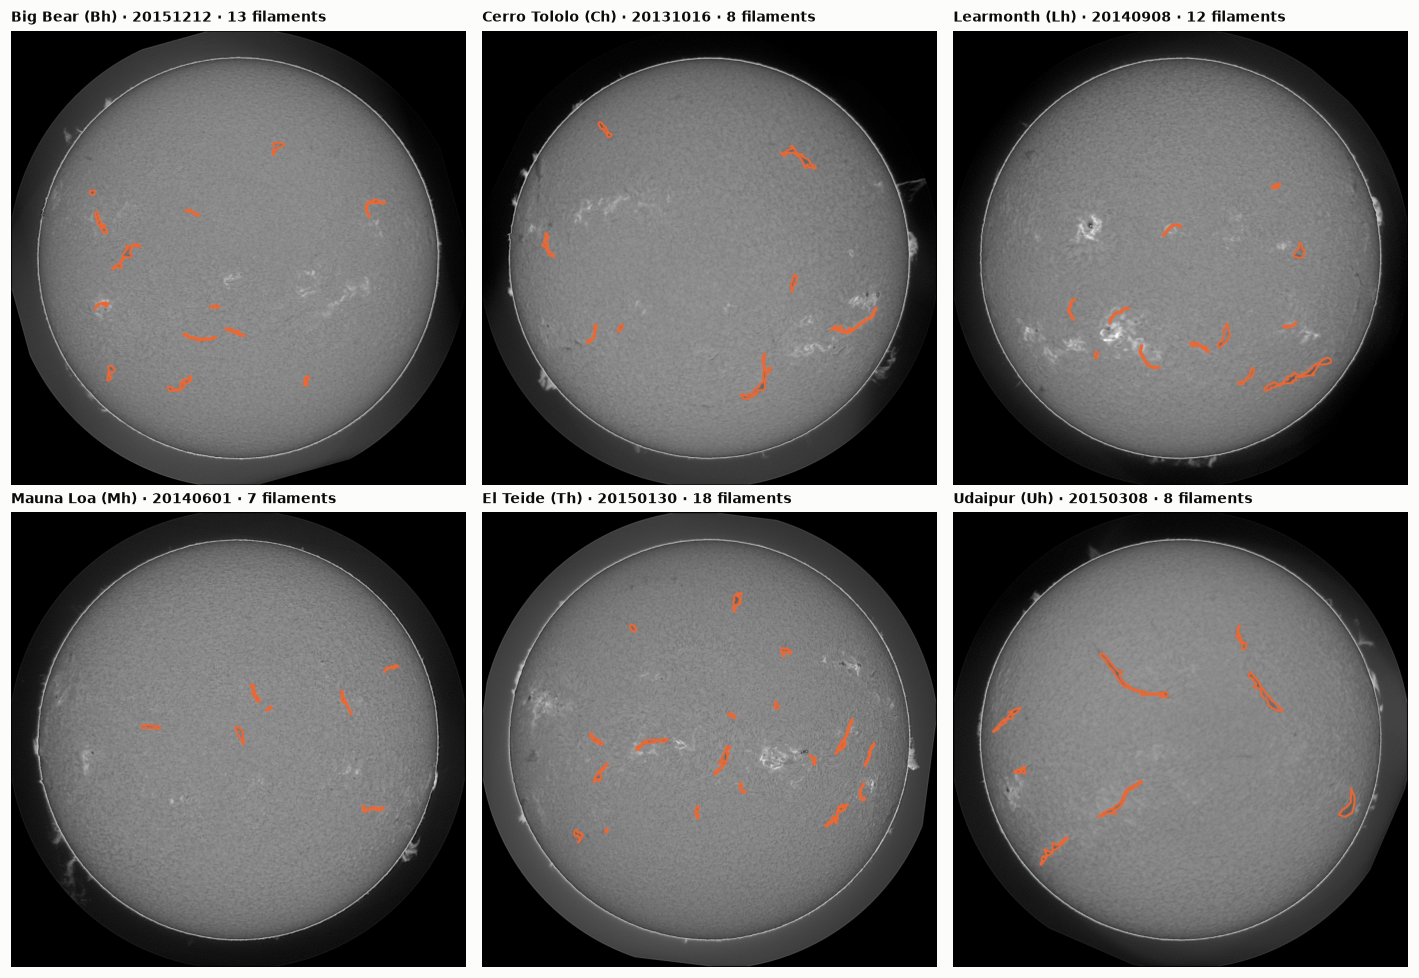

,cx,cy,r
count,887.00,887.00,887.00
mean,1023.01,1024.06,903.51
std,0.44,0.45,0.92
min,1021.45,1022.23,901.09
25%,1022.74,1023.74,902.93
50%,1023.01,1024.06,903.52
75%,1023.30,1024.38,904.08
max,1024.49,1025.36,905.99


In [14]:
rng = np.random.default_rng(3)
fig, axes = plt.subplots(2, 3, figsize=(13, 9))
for ax, site in zip(axes.flat, viz.SITE_ORDER):
    cand = [s for s in sets if s.site == site and len(s.polygons) >= 6]
    s = cand[rng.integers(len(cand))]
    img = load_image(image_path(s.observation))
    ov = A.overlay(img, s.instance_masks(), [viz.hex_to_rgb(viz.ACCENT)], thickness=7)
    ax.imshow(cv2.resize(ov, (768, 768), interpolation=cv2.INTER_AREA))
    ax.set_title(f"{SITES[site]} ({site}) · {s.observation[:8]} · {len(s.polygons)} filaments", fontsize=9)
    viz.no_axes(ax)
fig.tight_layout(); viz.save(fig, "eda_samples_per_site"); plt.show()
summary["disk"] = quality[["cx", "cy", "r"]].describe().loc[["mean", "std", "min", "max"]].round(2).to_dict()
quality[["cx", "cy", "r"]].describe().round(2)

Filaments are small, dark, elongated features scattered over the disk; most of the image is
background. Each frame also contains a grey **off-limb halo** (with bright prominences) whose outer
edge is irregular and often off-centre: a naive threshold finds the halo, not the Sun. Fitting the
limb itself (`fit_disk`, section 1.3) shows GONG frames are **already centred and scaled**: centre
within ±2 px of (1023, 1024), radius 901–906 px across all 887 images. No re-centring or rescaling
is needed, and a fixed disk mask suppresses the halo (filaments are on-disk features).

### Annotator agreement: the realistic ceiling

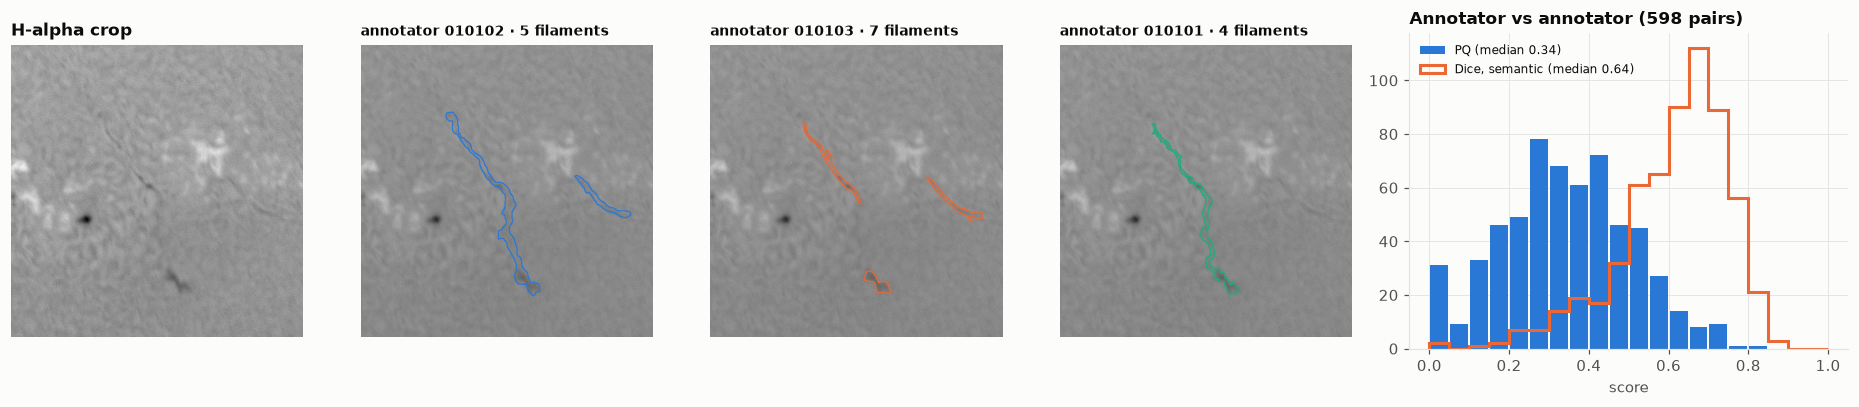

,mean,50%,std
pq,0.341,0.342,0.165
sq,0.597,0.624,0.149
rq,0.538,0.545,0.249
dice,0.614,0.641,0.138


In [15]:
summary["annotator_agreement"] = {
    "pairs": len(agree), "observations": int(agree.observation.nunique()),
    "pq_mean": float(agree.pq.mean()), "pq_median": float(agree.pq.median()),
    "dice_mean": float(agree.dice.mean()), "sq_mean": float(agree.sq.mean()), "rq_mean": float(agree.rq.mean()),
    "count_mismatch_mean": float((agree.n_a - agree.n_b).abs().mean()),
}
# An observation with 3 annotation sets whose agreement is close to the median (representative).
tri = agree.groupby("observation").filter(lambda g: len(g) == 3)
med = tri.groupby("observation").pq.mean()
obs = (med - agree.pq.median()).abs().idxmin()
group = [s for s in sets if s.observation == obs]
img = load_image(image_path(obs))
masks = {s.set_id: s.instance_masks() for s in group}
union = np.any([m for ms in masks.values() for m in ms], axis=0)
ys, xs = np.nonzero(union); cy, cx = int(np.median(ys)), int(np.median(xs)); H = 380
y0, x0 = max(cy - H, 0), max(cx - H, 0); crop = np.s_[y0:y0 + 2 * H, x0:x0 + 2 * H]

fig, axes = plt.subplots(1, 5, figsize=(17, 3.8), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.5]})
axes[0].imshow(img[crop], cmap="gray"); axes[0].set_title("H-alpha crop"); viz.no_axes(axes[0])
for ax, s, col in zip(axes[1:4], group, viz.SERIES):
    ax.imshow(A.overlay(img[crop], [m[crop] for m in masks[s.set_id]], [viz.hex_to_rgb(col)], thickness=2))
    ax.set_title(f"annotator {s.set_id.split('-')[0]} · {len(s.polygons)} filaments", fontsize=9); viz.no_axes(ax)
ax = axes[4]
ax.hist(agree.pq, bins=np.linspace(0, 1, 21), color=viz.SEQ, rwidth=0.9, label=f"PQ (median {agree.pq.median():.2f})")
ax.hist(agree.dice, bins=np.linspace(0, 1, 21), histtype="step", color=viz.ACCENT, linewidth=2,
        label=f"Dice, semantic (median {agree.dice.median():.2f})")
ax.set_title(f"Annotator vs annotator ({len(agree)} pairs)"); ax.set_xlabel("score"); ax.legend(loc="upper left", fontsize=8)
fig.tight_layout(); viz.save(fig, "eda_annotator_agreement"); plt.show()
agree[["pq", "sq", "rq", "dice"]].describe().T[["mean", "50%", "std"]].round(3)

**Reading.** Two independent experts score a mean PQ of only ≈ 0.34 against each other (matching the
public Kaggle notebook *"Filament PQ: Two Experts Agree at 0.34"*, which also validates our PQ
implementation), while semantic Dice is ≈ 0.61. Annotators agree *where* filament material is but
disagree on *how to cut it into instances* (one long filament vs several pieces; which faint segments
count). Consequences: labels are **noisy at the instance level**, which caps achievable PQ; all
annotation sets are kept as **separate training samples** (label-noise augmentation; all sets of an
observation share a fold); post-processing is tuned on validation PQ, because the instance
granularity is a convention learnt from the annotators.

### Filament geometry: scale, thinness, crowding, class imbalance

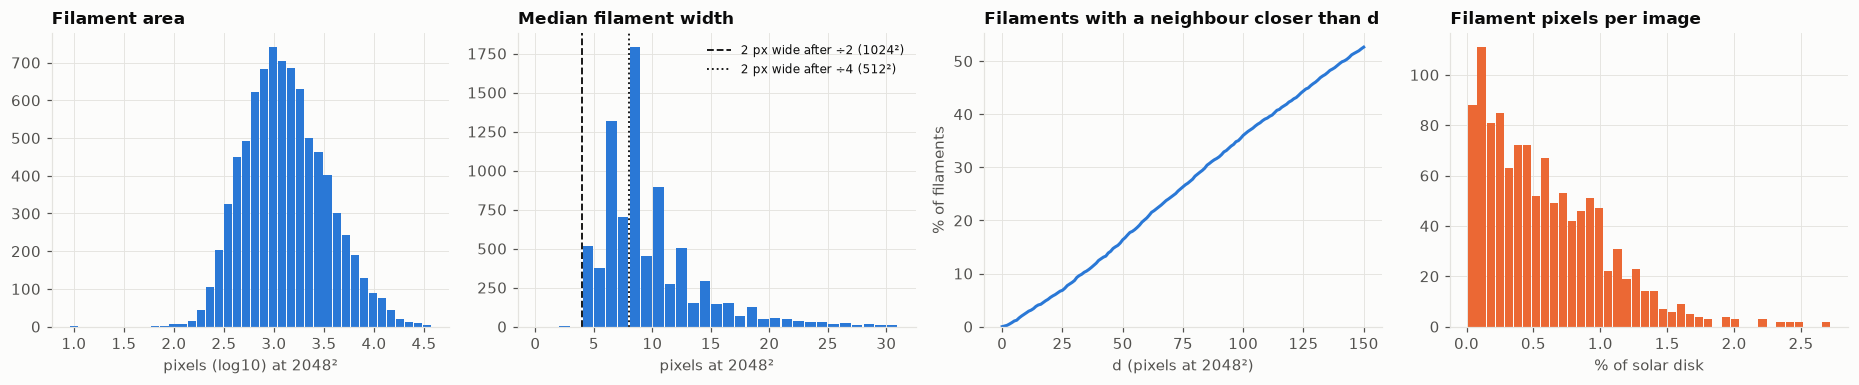

area_px_median                                       1228.0
width_median_px_median                             8.393799
width_median_px_p10_p90               [5.599976, 15.787567]
frac_width_lt_8px                                  0.356385
solidity_median                                    0.575039
frac_gap_lt_10px                                   0.025979
frac_gap_lt_25px                                   0.068423
frac_touching_other                                 0.00122
filaments_per_set_median                                7.0
filament_pixel_frac_of_disk_median                 0.004945
filament_pixel_frac_of_disk_p90                    0.011776
dtype: object

In [16]:
f = fil.query("area > 0")
summary["filament_geometry"] = {
    "area_px_median": float(f.area.median()),
    "width_median_px_median": float(f.width_median.median()),
    "width_median_px_p10_p90": f.width_median.quantile([.1, .9]).tolist(),
    "frac_width_lt_8px": float((f.width_median < 8).mean()),
    "solidity_median": float(f.solidity.median()),
    "frac_gap_lt_10px": float((f.gap_to_nearest < 10).mean()),
    "frac_gap_lt_25px": float((f.gap_to_nearest < 25).mean()),
    "frac_touching_other": float(f.touches_other.mean()),
    "filaments_per_set_median": float(per_set.n_filaments.median()),
    "filament_pixel_frac_of_disk_median": float(per_set.filament_frac.median()),
    "filament_pixel_frac_of_disk_p90": float(per_set.filament_frac.quantile(.9)),
}
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
ax = axes[0]
ax.hist(np.log10(f.area), bins=40, color=viz.SEQ, rwidth=0.9)
ax.set_title("Filament area"); ax.set_xlabel("pixels (log10) at 2048²")
ax = axes[1]
ax.hist(f.width_median, bins=np.arange(0, 32, 1), color=viz.SEQ, rwidth=0.9)
for d, ls, lab in [(2, "--", "2 px wide after ÷2 (1024²)"), (4, ":", "2 px wide after ÷4 (512²)")]:
    ax.axvline(2 * d, color=viz.TEXT, linestyle=ls, linewidth=1.2, label=lab)
ax.legend(fontsize=8, loc="upper right")
ax.set_title("Median filament width"); ax.set_xlabel("pixels at 2048²")
ax = axes[2]
d = np.arange(0, A.GAP_CAP + 1)
ax.plot(d, [(f.gap_to_nearest < x).mean() * 100 for x in d], color=viz.SEQ)
ax.set_ylim(0, None)
ax.set_title("Filaments with a neighbour closer than d"); ax.set_xlabel("d (pixels at 2048²)"); ax.set_ylabel("% of filaments")
ax = axes[3]
ax.hist(per_set.filament_frac * 100, bins=40, color=viz.ACCENT, rwidth=0.9)
ax.set_title("Filament pixels per image"); ax.set_xlabel("% of solar disk")
fig.tight_layout(); viz.save(fig, "eda_filament_geometry"); plt.show()
pd.Series(summary["filament_geometry"])

**Reading.**
* **Thin structures.** Width = 2 × distance-transform value along the skeleton. The median filament
  is ≈ 8 px wide (10–90 %: ≈ 6–16 px) at full resolution and a third are under 8 px. At 1024² those
  become < 4 px; at 512² they shrink to ≈ 2 px and fine barbs vanish → **input ≥ 1024²** (tested in E02/E03).
* **Crowding is rare; fragmentation is the instance problem.** Only ≈ 3 % of filaments have a
  neighbour within 10 px and touching polygons are ≈ 0.1 %, so connected components rarely merge two
  distinct filaments. The bigger risk is one filament predicted as a chain of separate blobs
  (**one-to-many** errors) → connectivity-aware losses and fragment merging (section 4).
* **Low solidity** (median ≈ 0.58): elongated, curved, branched shapes that bounding boxes fit poorly,
  so a box-based instance model (Mask R-CNN) is a poor fit; we use semantic segmentation + instance extraction.
* **Severe class imbalance.** Filament pixels are a median ≈ 0.5 % of the disk (≈ 1:200) → overlap
  losses (Dice/Tversky) or focal BCE and crops oversampled around filaments.

### Image quality across sites (noisy samples)

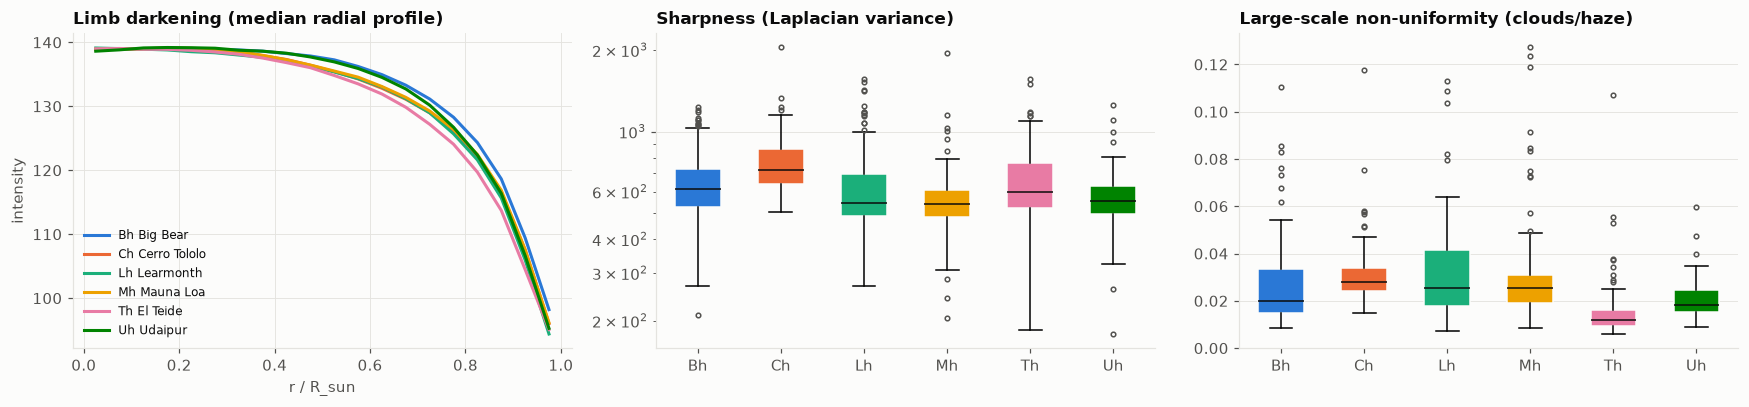

,median,iqr,sharpness,nonuniformity,r
site,,,,,
Bh,133.0,13.0,615.138,0.020,904.391
Ch,132.0,16.0,721.478,0.028,902.762
Lh,131.0,15.0,543.000,0.026,902.785
Mh,132.0,14.0,537.910,0.025,903.339
Th,130.0,16.0,596.669,0.012,903.787
Uh,133.0,14.0,554.842,0.018,904.199


In [17]:
prof_cols = [c for c in quality.columns if c.startswith("prof_")]
rr = (np.arange(len(prof_cols)) + 0.5) / len(prof_cols)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
ax = axes[0]
for site in viz.SITE_ORDER:
    p = quality.loc[quality.site == site, prof_cols].median()
    ax.plot(rr, p.values, color=viz.SITE_COLOR[site], label=f"{site} {SITES[site]}")
ax.set_title("Limb darkening (median radial profile)"); ax.set_xlabel("r / R_sun"); ax.set_ylabel("intensity"); ax.legend(fontsize=8)
for ax, col, title in [(axes[1], "sharpness", "Sharpness (Laplacian variance)"),
                       (axes[2], "nonuniformity", "Large-scale non-uniformity (clouds/haze)")]:
    data = [quality.loc[quality.site == s, col] for s in viz.SITE_ORDER]
    bp = ax.boxplot(data, tick_labels=viz.SITE_ORDER, patch_artist=True, widths=0.55, showfliers=True,
                    medianprops={"color": viz.TEXT}, flierprops={"markersize": 3, "markeredgecolor": viz.TEXT_2})
    for patch, s in zip(bp["boxes"], viz.SITE_ORDER):
        patch.set_facecolor(viz.SITE_COLOR[s]); patch.set_edgecolor(viz.SURFACE)
    ax.set_title(title); ax.grid(axis="x", visible=False)
axes[1].set_yscale("log")
fig.tight_layout(); viz.save(fig, "eda_quality_by_site"); plt.show()
quality.groupby("site")[["median", "iqr", "sharpness", "nonuniformity", "r"]].median().round(3)

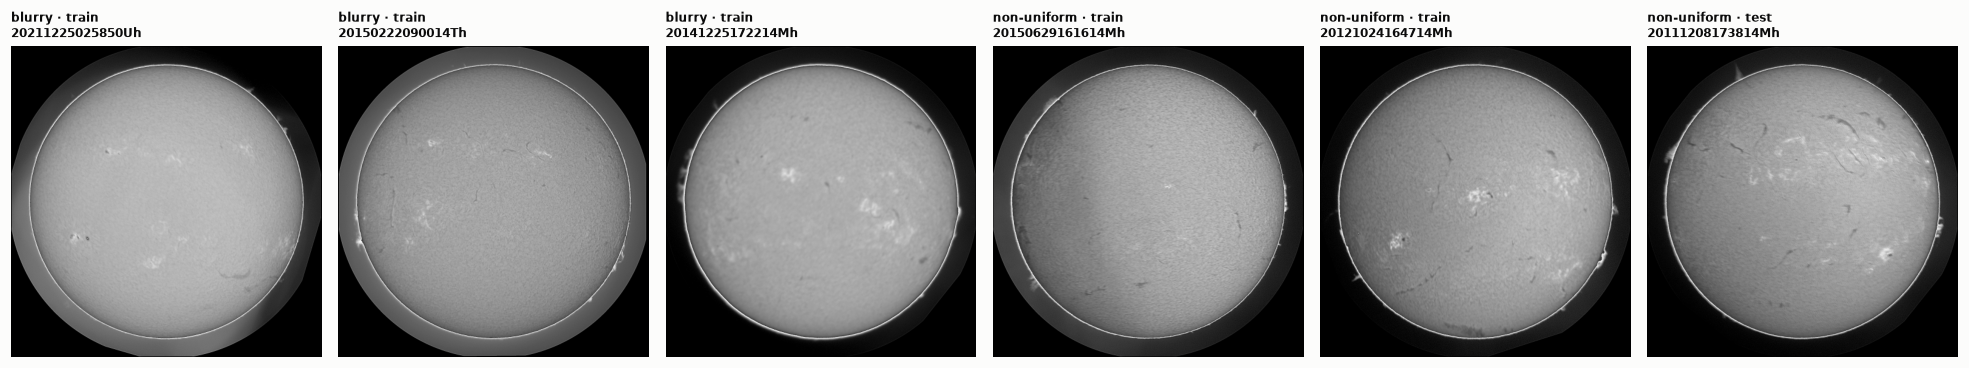

{'blurry': 9, 'nonuniform': 37, 'train': 35, 'test': 11}

In [18]:
# Outliers: robust z-score per metric over all images; show the worst offenders.
def robust_z(x):
    med = np.median(x); mad = np.median(np.abs(x - med)) * 1.4826
    return (x - med) / mad
quality["z_blur"] = -robust_z(np.log(quality.sharpness))
quality["z_cloud"] = robust_z(quality.nonuniformity)
flags = quality[(quality.z_blur > 3) | (quality.z_cloud > 3)]
summary["quality_outliers"] = {"blurry": int((quality.z_blur > 3).sum()), "nonuniform": int((quality.z_cloud > 3).sum()),
                               "train": int((flags.split == "train").sum()), "test": int((flags.split == "test").sum())}
worst = pd.concat([quality.nlargest(3, "z_blur").assign(why="blurry"),
                   quality.nlargest(3, "z_cloud").assign(why="non-uniform")])
fig, axes = plt.subplots(1, 6, figsize=(18, 3.4))
for ax, r in zip(axes, worst.itertuples()):
    ax.imshow(cv2.resize(load_image(image_path(r.observation)), (512, 512), interpolation=cv2.INTER_AREA), cmap="gray")
    ax.set_title(f"{r.why} · {r.split}\n{r.observation}", fontsize=8); viz.no_axes(ax)
fig.tight_layout(); viz.save(fig, "eda_quality_outliers"); plt.show()
summary["quality_outliers"]

**Reading.** Median disk brightness is similar across sites, but sharpness and especially
large-scale non-uniformity (haze, cloud gradients) differ by site: El Teide (Th) is the most uniform,
Cerro Tololo (Ch) the sharpest. Robust outlier flags (|z| > 3) mark a few dozen images as unusually
blurry or non-uniform, in **both train and test**, so they are **kept**, and the model is made robust
to them instead: limb-darkening flattening + disk-wise normalisation (1.3) remove the site-to-site
brightness and centre-to-limb trend, and photometric augmentation (contrast, brightness, blur, noise;
1.4) covers the rest.

### Summary → decisions

| Finding | Decision |
|---|---|
| Disk is fixed (centre ±2 px, r ≈ 903 px); off-limb halo is irregular | edge-based disk fit, pixels beyond 0.99 R set to 0 |
| Median filament ≈ 8 px wide, ⅓ < 8 px | network input ≥ 1024² (`scale ≥ 0.5`), never whole-disk 512² |
| Filaments ≈ 0.5 % of disk pixels (≈ 1:200) | Dice/Tversky/focal losses; 70 % of crops centred on a filament |
| Neighbours rarely touch; experts split/merge differently | instance = connected component; tune post-processing on PQ; fragment merging (section 4) |
| Expert-vs-expert PQ ≈ 0.34 | realistic ceiling; noisy instance labels → keep all annotation sets |
| Site-dependent haze/blur/contrast; outliers in train and test | limb flattening + robust normalisation; photometric augmentation |
| Test interleaved in time with train | validation by 27-day blocks (honest, slightly pessimistic) |

## 1.3 Preprocessing

1. **Disk fit** (`fit_disk`): steepest radial intensity drop along 360 rays within ±6 % of the
   nominal GONG limb + robust circle fit (3 refits dropping outlier rays). A naive threshold finds the
   off-limb halo instead of the limb (it gave a wrong radius on 160 images in our first version).
2. **Limb-darkening flattening**: divide by the image's median radial profile (256 radial bins).
3. **Normalisation**: `x = (flat − 1) / robust std` → filaments negative, plage positive, one scale for
   all sites; pixels beyond 0.99 R (halo + JPEG limb ring) set to 0, values clipped to ±8.
4. **Cache**: disk geometry, radial profiles and rasterised instance label maps (`data/processed/`,
   21 MB), so training reads only the JPEG and the cache.

In [19]:
%%writefile src/filaments/preprocess.py
"""Disk-aware preprocessing and the on-disk cache it needs.

Per image we store the fitted disk (cx, cy, r) and a robust radial intensity profile (median per
radial bin = limb darkening). An image is normalised as

    flat = raw / profile(rho)            # removes centre-to-limb darkening (rho = r / R_sun)
    x    = (flat - 1) / spread           # spread = robust std of flat on the disk
    x    = 0 outside the limb            # the off-limb halo carries no filaments

so filaments are negative, plage positive, and all sites share one intensity scale (EDA §6).
Label maps (instance ids per annotation set) are rasterised once and cached as PNG.

Build the cache with:  python -m filaments.preprocess
"""
from __future__ import annotations

import json
import os
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import cv2
import numpy as np
from scipy import ndimage

from .data import (PROJECT_ROOT, TEST_IMAGES, TRAIN_IMAGES, AnnotationSet, fit_disk, load_annotation_sets,
                   load_image)

# Must be writable (the Kaggle input dir is read-only).
CACHE_DIR = Path(os.environ.get("FILAMENT_CACHE", PROJECT_ROOT / "data" / "processed"))
LABEL_DIR = CACHE_DIR / "labels"
PROFILE_FILE = CACHE_DIR / "profiles.npz"

N_BINS = 256          # radial bins over rho in [0, 1]
LIMB_MARGIN = 0.99    # cut just inside the limb: the JPEG limb has a bright/dark ring artifact
CLIP = 8.0            # |x| clip in robust-std units


def radial_profile(img: np.ndarray, cx: float, cy: float, r: float) -> np.ndarray:
    """Median intensity per radial bin, lightly smoothed. Medians ignore filaments/plage."""
    yy, xx = np.indices(img.shape)
    rho = np.hypot(xx - cx, yy - cy) / r
    on = rho < 1.0
    bins = np.minimum((rho[on] * N_BINS).astype(int), N_BINS - 1)
    prof = np.asarray(ndimage.median(img[on].astype(np.float32), labels=bins, index=np.arange(N_BINS)))
    prof = np.nan_to_num(prof, nan=np.nanmedian(prof))
    k = np.ones(5) / 5
    smooth = np.convolve(np.pad(prof, 2, mode="edge"), k, mode="valid")
    return np.maximum(smooth, 1.0).astype(np.float32)


def normalise(raw: np.ndarray, rho: np.ndarray, profile: np.ndarray, spread: float) -> np.ndarray:
    """raw: sampled intensities; rho: r/R at the same pixels (any shape). Returns float32 x."""
    idx = np.clip(rho * N_BINS, 0, N_BINS - 1)
    lo = np.floor(idx).astype(int)
    hi = np.minimum(lo + 1, N_BINS - 1)
    w = (idx - lo).astype(np.float32)
    prof = profile[lo] * (1 - w) + profile[hi] * w
    x = (raw.astype(np.float32) / prof - 1.0) / spread
    x[rho > LIMB_MARGIN] = 0.0
    return np.clip(x, -CLIP, CLIP)


def full_image(raw: np.ndarray, disk: tuple[float, float, float], profile: np.ndarray, spread: float) -> np.ndarray:
    cx, cy, r = disk
    yy, xx = np.indices(raw.shape, dtype=np.float32)
    rho = np.hypot(xx - cx, yy - cy) / r
    return normalise(raw, rho, profile, spread)


# ---------------------------------------------------------------- cache building

def _image_entry(path: Path) -> tuple[str, np.ndarray, np.ndarray]:
    raw = load_image(path)
    disk = fit_disk(raw)
    prof = radial_profile(raw, *disk)
    flat = full_image(raw, disk, prof, spread=1.0)  # x with spread 1 = flat - 1
    cx, cy, r = disk
    yy, xx = np.indices(raw.shape)
    inner = np.hypot(xx - cx, yy - cy) < 0.95 * r
    v = flat[inner]
    spread = float(1.4826 * np.median(np.abs(v - np.median(v))))
    return path.stem, np.array([*disk, spread], np.float32), prof


def _label_entry(s: AnnotationSet) -> None:
    out = LABEL_DIR / f"{s.set_id}.png"
    if not out.exists():
        lab = s.label_map()
        assert lab.max() < 2**16
        cv2.imwrite(str(out), lab.astype(np.uint16))


def build_cache(workers: int = 8) -> None:
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    LABEL_DIR.mkdir(parents=True, exist_ok=True)
    if not PROFILE_FILE.exists():
        paths = sorted(TRAIN_IMAGES.glob("*.jpeg")) + sorted(TEST_IMAGES.glob("*.jpeg"))
        with ProcessPoolExecutor(workers) as ex:
            rows = list(ex.map(_image_entry, paths, chunksize=8))
        np.savez(PROFILE_FILE, names=np.array([r[0] for r in rows]),
                 geom=np.stack([r[1] for r in rows]), profiles=np.stack([r[2] for r in rows]))
    sets = load_annotation_sets()
    with ProcessPoolExecutor(workers) as ex:
        list(ex.map(_label_entry, sets, chunksize=8))
    (CACHE_DIR / "README.json").write_text(json.dumps({
        "profiles": "names, geom=[cx, cy, r, spread], profiles=[N, N_BINS] median radial intensity",
        "labels": "uint16 instance label maps per annotation set (0 = background)",
    }, indent=2))


class ProfileStore:
    """Lookup of per-image disk geometry, spread and radial profile."""

    def __init__(self, path: Path = PROFILE_FILE):
        z = np.load(path)
        self.index = {str(n): i for i, n in enumerate(z["names"])}
        self.geom, self.profiles = z["geom"], z["profiles"]

    def __call__(self, observation: str) -> tuple[tuple[float, float, float], np.ndarray, float]:
        i = self.index[observation]
        cx, cy, r, spread = self.geom[i]
        return (float(cx), float(cy), float(r)), self.profiles[i], float(spread)


def load_labels(set_id: str) -> np.ndarray:
    lab = cv2.imread(str(LABEL_DIR / f"{set_id}.png"), cv2.IMREAD_UNCHANGED)
    if lab is None:
        raise FileNotFoundError(set_id)
    return lab.astype(np.int32)


if __name__ == "__main__":
    build_cache()
    print("cache ready:", CACHE_DIR)

Overwriting src/filaments/preprocess.py


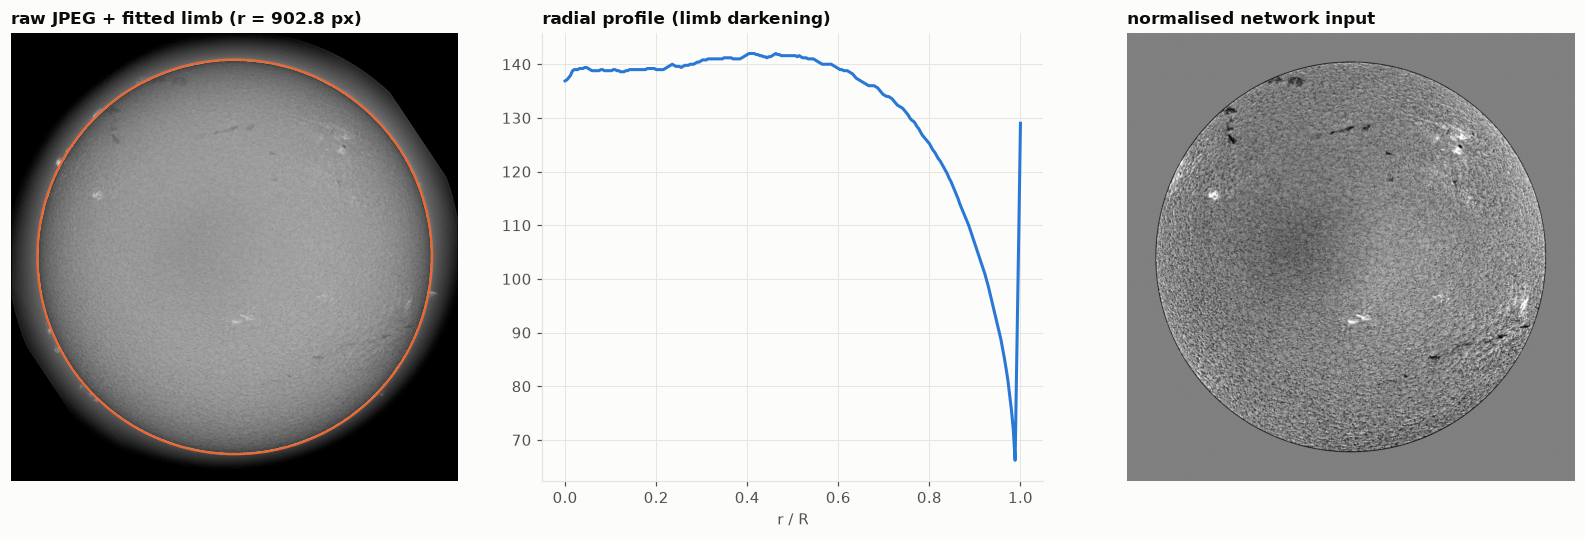

In [20]:
from filaments.preprocess import build_cache, CACHE_DIR, ProfileStore, full_image
build_cache(workers=os.cpu_count())          # ~5 min once; skipped when the cache exists
ps = ProfileStore()
obs = train_obs[0]
raw = load_image(image_path(obs)); disk, prof, spread = ps(obs)
x = full_image(raw, disk, prof, spread)
cx, cy, r = disk[:3]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(raw, cmap="gray"); axes[0].add_patch(plt.Circle((cx, cy), r, fill=False, color=viz.ACCENT, lw=1.5))
axes[0].set_title(f"raw JPEG + fitted limb (r = {r:.1f} px)")
axes[1].plot(np.linspace(0, 1, len(prof)), prof, color=viz.SEQ); axes[1].set_title("radial profile (limb darkening)"); axes[1].set_xlabel("r / R")
axes[2].imshow(x, cmap="gray", vmin=-4, vmax=4); axes[2].set_title("normalised network input")
for a in (axes[0], axes[2]): viz.no_axes(a)
fig.tight_layout(); viz.save(fig, "prep_pipeline"); plt.show()

## 1.4 Augmentation

One affine warp per crop combines the resolution change, free rotation (a solar disk has no preferred
orientation), flip, ±10 % zoom and translation; normalisation is evaluated only at the sampled pixels
(fast, no 2048² intermediate). Photometric augmentation (contrast, brightness, blur ≈ poor seeing,
Gaussian noise) covers the site-to-site variation found in 1.2. 70 % of crops are centred on a
random filament (class imbalance). Whether augmentation helps is tested in E06.

In [21]:
%%writefile src/filaments/dataset.py
"""Training / validation datasets.

Training samples are random crops. Each crop is produced by ONE affine warp from the raw 2048²
image (rotation, flip, scale jitter, translation and the resolution change all at once), and the
disk normalisation is evaluated only at the sampled pixels, so a crop costs crop-sized work.

label_mode
  "separate": every annotation set is its own sample (Kaggle's suggestion; label noise as augmentation)
  "soft":     one sample per observation; target = mean of its annotators' masks (consensus in [0,1])
"""
from __future__ import annotations

import math
import random
from dataclasses import dataclass

import cv2
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset

from .data import AnnotationSet, image_path, load_image
from .preprocess import LIMB_MARGIN, ProfileStore, full_image, load_labels, normalise


@dataclass
class CropConfig:
    crop: int = 512            # output crop size (pixels at model resolution)
    scale: float = 0.5         # model resolution / native resolution (0.5 -> disk seen at 1024²)
    pos_frac: float = 0.7      # probability that a crop is centred on a filament pixel
    rotate: bool = True        # free rotation (a solar disk has no preferred orientation)
    scale_jitter: float = 0.1  # +-10 % zoom
    photometric: bool = True   # contrast/brightness/blur/noise (site-to-site variation, EDA §6)


def _affine(center_xy, out_size, scale, angle_deg, flip):
    """2x3 matrix mapping *source* pixel coords -> output crop coords."""
    c, s = math.cos(math.radians(angle_deg)), math.sin(math.radians(angle_deg))
    R = np.array([[c, -s], [s, c]]) * scale
    if flip:
        R = R @ np.diag([-1.0, 1.0])
    t = np.array([out_size / 2, out_size / 2]) - R @ np.asarray(center_xy)
    return np.c_[R, t].astype(np.float32)


def _photometric(x: np.ndarray, rng: random.Random) -> np.ndarray:
    x = x * rng.uniform(0.8, 1.25) + rng.uniform(-0.3, 0.3)
    if rng.random() < 0.3:
        x = cv2.GaussianBlur(x, (0, 0), rng.uniform(0.5, 1.5))      # poor seeing
    if rng.random() < 0.3:
        x = x + np.random.normal(0, rng.uniform(0.05, 0.25), x.shape).astype(np.float32)
    return x


class CropDataset(Dataset):
    def __init__(self, sets: list[AnnotationSet], cfg: CropConfig, label_mode: str = "separate",
                 samples_per_epoch: int | None = None, seed: int = 0):
        self.cfg, self.label_mode = cfg, label_mode
        by_obs: dict[str, list[AnnotationSet]] = {}
        for s in sets:
            by_obs.setdefault(s.observation, []).append(s)
        if label_mode == "separate":
            self.items = [(s.observation, [s.set_id]) for s in sets]
        elif label_mode == "soft":
            self.items = [(o, [s.set_id for s in g]) for o, g in by_obs.items()]
        else:
            raise ValueError(label_mode)
        self.n = samples_per_epoch or len(self.items)
        self.seed = seed
        self.profiles = None  # opened lazily per worker

    def __len__(self):
        return self.n

    def __getitem__(self, i):
        if self.profiles is None:
            self.profiles = ProfileStore()
        rng = random.Random((self.seed, i, torch.initial_seed()).__hash__())
        obs, set_ids = self.items[rng.randrange(len(self.items))]
        cfg = self.cfg
        raw = load_image(image_path(obs))
        disk, profile, spread = self.profiles(obs)
        labels = [load_labels(sid) for sid in set_ids]

        if rng.random() < cfg.pos_frac:
            lab = labels[rng.randrange(len(labels))]
            ys, xs = np.nonzero(lab)
            k = rng.randrange(len(ys))
            jitter = cfg.crop / cfg.scale / 4
            center = (xs[k] + rng.uniform(-jitter, jitter), ys[k] + rng.uniform(-jitter, jitter))
        else:  # anywhere on the disk
            cx, cy, r = disk
            rr, th = r * math.sqrt(rng.random()), rng.uniform(0, 2 * math.pi)
            center = (cx + rr * math.cos(th), cy + rr * math.sin(th))

        scale = cfg.scale * (1 + rng.uniform(-cfg.scale_jitter, cfg.scale_jitter))
        angle = rng.uniform(0, 360) if cfg.rotate else rng.choice([0, 90, 180, 270])
        M = _affine(center, cfg.crop, scale, angle, flip=rng.random() < 0.5)
        size = (cfg.crop, cfg.crop)

        if scale < 0.75:  # anti-alias before a strong downsample
            raw = cv2.GaussianBlur(raw, (0, 0), 0.5 / scale)
        img = cv2.warpAffine(raw, M, size, flags=cv2.INTER_LINEAR, borderValue=0)
        # rho at each output pixel, via the inverse map (only crop-sized work)
        Minv = cv2.invertAffineTransform(M)
        oy, ox = np.indices(size, dtype=np.float32)
        sx = Minv[0, 0] * ox + Minv[0, 1] * oy + Minv[0, 2]
        sy = Minv[1, 0] * ox + Minv[1, 1] * oy + Minv[1, 2]
        rho = np.hypot(sx - disk[0], sy - disk[1]) / disk[2]
        x = normalise(img, rho, profile, spread)

        masks = [cv2.warpAffine(lab.astype(np.float32), M, size, flags=cv2.INTER_NEAREST) for lab in labels]
        instance = masks[0].astype(np.int32)
        target = np.mean([m > 0 for m in masks], axis=0).astype(np.float32)

        if cfg.photometric:
            x = _photometric(x, rng)
            x[rho > LIMB_MARGIN] = 0.0
        return {
            "image": torch.from_numpy(x[None].astype(np.float32)),
            "mask": torch.from_numpy(target[None]),
            "instances": torch.from_numpy(instance),   # for instance-aware targets (enhancement work)
        }


def full_disk_input(observation: str, scale: float, profiles: ProfileStore | None = None) -> np.ndarray:
    """Whole normalised disk at model resolution: float32 (H*scale, W*scale). Used for val/test."""
    profiles = profiles or ProfileStore()
    raw = load_image(image_path(observation))
    disk, profile, spread = profiles(observation)
    x = full_image(raw, disk, profile, spread)
    if scale != 1.0:
        size = int(round(raw.shape[1] * scale))
        x = cv2.resize(x, (size, size), interpolation=cv2.INTER_AREA)
    return x


def load_folds(path) -> pd.DataFrame:
    return pd.read_csv(path)

Overwriting src/filaments/dataset.py


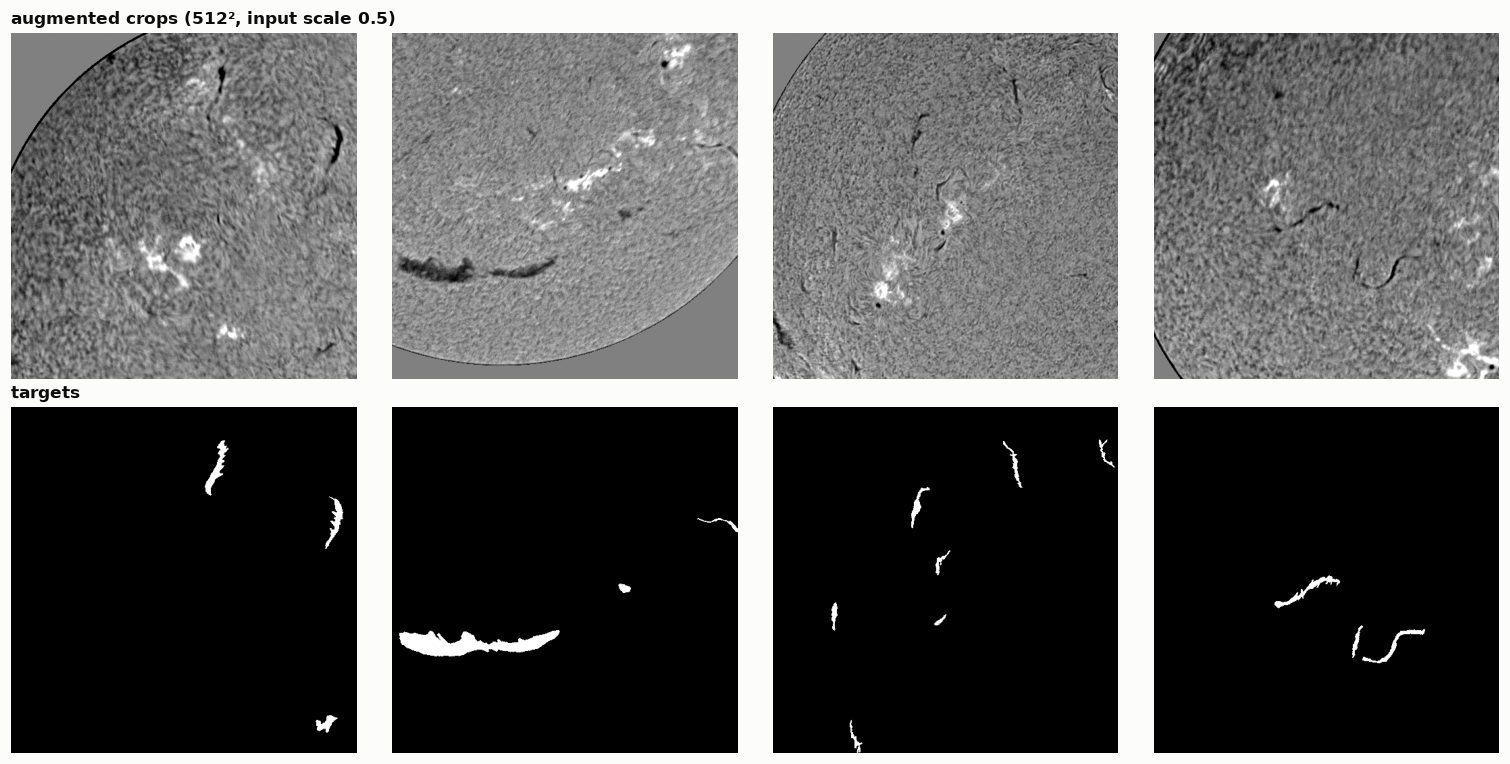

In [22]:
from filaments.dataset import CropDataset, CropConfig
ds = CropDataset(sets, CropConfig(scale=CONFIG["scale"], crop=CONFIG["crop"]), samples_per_epoch=8)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i in range(4):
    b = ds[i]
    axes[0, i].imshow(b["image"][0], cmap="gray", vmin=-4, vmax=4); viz.no_axes(axes[0, i])
    axes[1, i].imshow(b["mask"][0], cmap="gray"); viz.no_axes(axes[1, i])
axes[0, 0].set_title("augmented crops (512², input scale 0.5)"); axes[1, 0].set_title("targets")
fig.tight_layout(); viz.save(fig, "prep_augmented_crops"); plt.show()

## 1.5 Train/validation split

5 folds over **observations**, grouped into **27-day blocks** (≈ one solar rotation): all annotation
sets of an observation, and the same filament seen on consecutive days, always land in the same fold.
Blocks are distributed greedily to balance fold sizes. Deterministic (seed 0). All methodology
comparisons use fold 0; the final configuration is trained on all 5 folds (section 2.9).

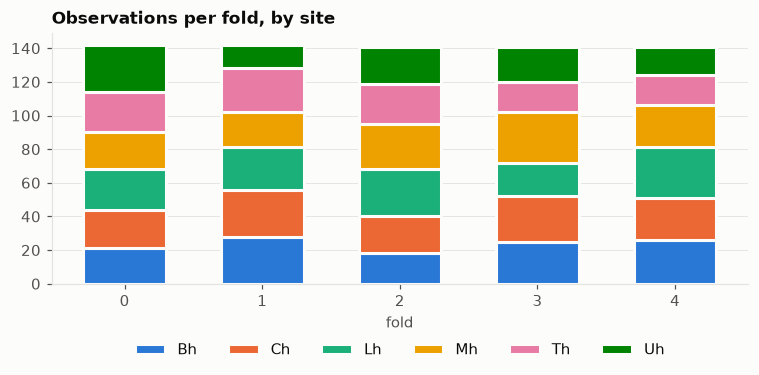

{'observations_per_fold': [142, 142, 141, 141, 141],
 'annotation_sets_per_fold': [235, 250, 217, 206, 246],
 'consecutive_same_day_pairs_split_across_folds': 5}

In [23]:
fold_of = make_folds(train_obs, n_folds=5, days=27, seed=0)
folds = meta.query("split == 'train'")[["observation", "site", "year", "time"]].copy()
folds["fold"] = folds.observation.map(fold_of)
folds["n_sets"] = folds.observation.map(sets_per_obs)
folds.to_csv("data/folds.csv", index=False)

# Sanity: every observation in exactly one fold; how many same-day neighbours fall across a block edge.
assert folds.observation.is_unique
t_sorted = folds.sort_values("time")
close = (t_sorted.time.diff().dt.total_seconds() < 86400)
summary["folds"] = {
    "observations_per_fold": folds.fold.value_counts().sort_index().tolist(),
    "annotation_sets_per_fold": folds.groupby("fold").n_sets.sum().tolist(),
    "consecutive_same_day_pairs_split_across_folds": int((close & (t_sorted.fold.diff() != 0)).sum()),
}
tab = folds.pivot_table(index="fold", columns="site", values="observation", aggfunc="count").reindex(columns=viz.SITE_ORDER).fillna(0)
fig, ax = plt.subplots(figsize=(7, 3.6))
bottom = np.zeros(len(tab))
for s in viz.SITE_ORDER:
    ax.bar(tab.index, tab[s], 0.6, bottom=bottom, color=viz.SITE_COLOR[s], label=s, edgecolor=viz.SURFACE, linewidth=2)
    bottom += tab[s].values
ax.set_title("Observations per fold, by site"); ax.set_xlabel("fold"); ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax.grid(axis="x", visible=False)
fig.tight_layout(); viz.save(fig, "eda_folds"); plt.show()
(EDA / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
summary["folds"]

A handful of same-day pairs fall either side of a block boundary (count above): a small, accepted
leak. Site mix per fold stays close to the overall mix.

# 2. Experimental Setup & Methodology

**Tools.** PyTorch 2, segmentation_models_pytorch 0.5 (U-Net/U-Net++ with ImageNet encoders),
pycocotools (RLE, IoU), OpenCV, NumPy/pandas, Matplotlib.
**Hardware.** All reported runs: Kaggle NVIDIA T4 (16 GB) through private GPU kernels driven by
`tools/kaggle_run.py` (2.5); analysis on Colab / a laptop (Apple M-series, MPS).

**Protocol** (every comparison): validation fold 0 (141 observations, 235 annotation sets), 20 epochs
× 1000 random 512² crops, batch 8, checkpoint selected by validation PQ, post-processing tuned on the
saved out-of-fold probabilities, **one change per experiment**, baseline repeated with 3 seeds.

## 2.1 Evaluation metric: local Panoptic Quality
### IoU and matching

PQ (Kirillov et al., 2019) matches a predicted and a ground-truth filament when IoU > 0.5. Above 0.5
a segment can overlap at most one segment of the other set, so matching is unique: no Hungarian
assignment needed. IoUs are computed on COCO RLEs with `pycocotools` (fast at 2048²).

The implementation is `src/filaments/metrics.py`, written in section 1.1 because the annotator-agreement analysis (1.2) already uses it.

### PQ computation

`PQ = Σ_TP IoU / (|TP| + ½|FP| + ½|FN|) = SQ × RQ`. Reported both dataset-level (`pq_global`,
headline: sums of TP/FP/FN/IoU over all validation images) and as the mean of per-image PQ, plus
one-to-many (fragmentation) and many-to-one (over-merging) counts, which the competition also
inspects. Each annotation set of a validation image is scored as its own ground truth.

In [24]:
from filaments.metrics import image_stats, aggregate, dice
def box(y0, y1, x0, x1, n=64):
    m = np.zeros((n, n), bool); m[y0:y1, x0:x1] = True; return m
s = image_stats([box(0, 10, 0, 10)], [box(0, 10, 0, 8), box(50, 60, 50, 60)])
print(f"one match (IoU 0.8) + one FP -> PQ {s.pq:.3f} (expected {0.8 / 1.5:.3f}), SQ {s.sq:.2f}, RQ {s.rq:.3f}")

one match (IoU 0.8) + one FP -> PQ 0.533 (expected 0.533), SQ 0.80, RQ 0.667


### Sanity tests

Unit tests of the edge cases PQ must punish, plus a check on real data: our implementation gives
expert-vs-expert PQ ≈ 0.34 (section 1.2), matching the public Kaggle notebook *"Filament PQ: Two
Experts Agree at 0.34"*.

In [25]:
from filaments import rle
g = [box(0, 10, 0, 10), box(20, 40, 20, 40)]
assert np.isclose(image_stats(g, g).pq, 1.0), "perfect prediction"
s = image_stats([box(0, 10, 0, 40)], [box(0, 10, 0, 20), box(0, 10, 20, 40)])
assert s.tp == 0 and s.fp == 2 and s.fn == 1 and s.one_to_many == 1, "fragmentation is penalised"
s = image_stats([box(0, 10, 0, 10), box(0, 10, 30, 40)], [box(0, 10, 0, 40)])
assert s.tp == 0 and s.many_to_one == 1, "over-merging is penalised"
assert image_stats([], []).fn == 0 and image_stats(g, []).fn == 2, "empty cases"
m = np.zeros((2048, 2048), bool); m[100:300, 50:900] = True
assert (rle.decode(rle.encode(m)) == m).all(), "RLE round trip (submission format)"
assert abs(agree.pq.mean() - 0.34) < 0.02, "expert-vs-expert PQ matches the public reference"
print("all PQ / RLE sanity tests passed")

all PQ / RLE sanity tests passed


## 2.2 Problem formulation & architecture

**Formulation:** semantic segmentation (filament probability per pixel) followed by **instance
extraction** (threshold → 8-connected components → minimum area). Section 1.2 motivates it: filaments
rarely touch (components separate them), and their elongated, branched shapes fit bounding boxes
poorly (box-based Mask R-CNN). The remaining instance errors are handled in section 4.

**Baseline:** U-Net (Ronneberger et al., 2015) with an ImageNet-pretrained ResNet-34 encoder
(segmentation_models_pytorch). The single grayscale channel is handled by summing the pretrained RGB
filters of the first convolution (no fake RGB). Compared alternatives: U-Net++, EfficientNet-B3
encoder, no pre-training (2.6).

In [26]:
%%writefile src/filaments/models.py
"""Model construction (segmentation_models_pytorch) and size reporting."""
from __future__ import annotations

import io

import segmentation_models_pytorch as smp
import torch
from torch import nn


def build_model(arch: str = "unet", encoder: str = "resnet34", weights: str | None = "imagenet",
                in_channels: int = 1, classes: int = 1) -> nn.Module:
    """Single-channel input: smp adapts the pretrained first conv by summing its RGB filters, which
    is the right thing for a grayscale H-alpha image (no fake RGB replication needed)."""
    return smp.create_model(arch, encoder_name=encoder, encoder_weights=weights,
                            in_channels=in_channels, classes=classes)


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters())


def size_mb(model: nn.Module) -> float:
    """Serialized state_dict size (what ships in the repo / submission)."""
    buf = io.BytesIO()
    torch.save(model.state_dict(), buf)
    return buf.tell() / 2**20


def pick_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

Overwriting src/filaments/models.py


In [27]:
from filaments.models import build_model, count_params, size_mb
m = build_model(CONFIG["arch"], CONFIG["encoder"], CONFIG["weights"])
print(f"{CONFIG['arch']} / {CONFIG['encoder']}: {count_params(m) / 1e6:.1f} M parameters, {size_mb(m):.1f} MB")

unet / resnet34: 24.4 M parameters, 93.4 MB


## 2.3 Loss functions

Combined as a weighted-sum string, e.g. `"bce:1,dice:1"`. Overlap losses are computed over the whole
batch so crops without filaments are well defined. BCE gives stable per-pixel gradients, Dice
counters the 1:200 imbalance; focal + Tversky (β > α, favours recall of faint/thin structure) is the
imbalance-focused alternative (E04); clDice (soft skeletons) rewards connectivity (section 4).

In [28]:
%%writefile src/filaments/losses.py
"""Segmentation losses. All take raw logits (B,1,H,W) and targets in [0,1] (soft labels allowed).

Specified as a weighted sum string, e.g. "bce:1,dice:1" or "focal:1,tversky:1,cldice:0.5".
Overlap losses are computed over the whole batch (not per crop), so crops without any filament
do not produce undefined or exploding per-sample Dice terms.
"""
from __future__ import annotations

import torch
import torch.nn.functional as F


def bce(logits, target):
    return F.binary_cross_entropy_with_logits(logits, target)


def focal(logits, target, gamma: float = 2.0, alpha: float = 0.75):
    p = torch.sigmoid(logits)
    ce = F.binary_cross_entropy_with_logits(logits, target, reduction="none")
    p_t = p * target + (1 - p) * (1 - target)
    a_t = alpha * target + (1 - alpha) * (1 - target)
    return (a_t * (1 - p_t) ** gamma * ce).mean()


def dice(logits, target, eps: float = 1.0):
    p = torch.sigmoid(logits)
    inter = (p * target).sum()
    return 1 - (2 * inter + eps) / (p.sum() + target.sum() + eps)


def tversky(logits, target, alpha: float = 0.3, beta: float = 0.7, eps: float = 1.0):
    """beta > alpha penalises false negatives more: favours recall of thin/faint structure."""
    p = torch.sigmoid(logits)
    tp = (p * target).sum()
    fp = (p * (1 - target)).sum()
    fn = ((1 - p) * target).sum()
    return 1 - (tp + eps) / (tp + alpha * fp + beta * fn + eps)


# ---- clDice (Shit et al., CVPR 2021): overlap of soft skeletons -> rewards topological continuity

def _soft_erode(x):
    return -F.max_pool2d(-x, 3, 1, 1)


def _soft_dilate(x):
    return F.max_pool2d(x, 3, 1, 1)


def soft_skeleton(x, iters: int = 10):
    skel = F.relu(x - _soft_dilate(_soft_erode(x)))
    for _ in range(iters):
        x = _soft_erode(x)
        delta = F.relu(x - _soft_dilate(_soft_erode(x)))
        skel = skel + F.relu(delta - skel * delta)
    return skel


def cldice(logits, target, iters: int = 10, eps: float = 1.0):
    p = torch.sigmoid(logits)
    sp, st = soft_skeleton(p, iters), soft_skeleton(target, iters)
    tprec = ((sp * target).sum() + eps) / (sp.sum() + eps)
    tsens = ((st * p).sum() + eps) / (st.sum() + eps)
    return 1 - 2 * tprec * tsens / (tprec + tsens)


LOSSES = {"bce": bce, "focal": focal, "dice": dice, "tversky": tversky, "cldice": cldice}


class Combined:
    def __init__(self, spec: str):
        self.terms = []
        for part in spec.split(","):
            name, w = part.split(":") if ":" in part else (part, "1")
            self.terms.append((name.strip(), LOSSES[name.strip()], float(w)))

    def __call__(self, logits, target):
        parts = {name: fn(logits.float(), target) for name, fn, _ in self.terms}
        total = sum(w * parts[name] for name, _, w in self.terms)
        return total, {k: float(v.detach()) for k, v in parts.items()}

Overwriting src/filaments/losses.py


In [29]:
from filaments.losses import Combined
logits = torch.randn(2, 1, 64, 64); target = (torch.rand(2, 1, 64, 64) > 0.95).float()
for spec in ["bce:1,dice:1", "focal:1,tversky:1", "bce:1,dice:1,cldice:0.5"]:
    total, parts = Combined(spec)(logits, target)
    print(f"{spec:28s} total {total.item():.3f}  {parts}")

bce:1,dice:1                 total 1.715  {'bce': 0.8055994510650635, 'dice': 0.9093388915061951}
focal:1,tversky:1            total 0.959  {'focal': 0.09460607916116714, 'tversky': 0.8648048639297485}
bce:1,dice:1,cldice:0.5      total 2.169  {'bce': 0.8055994510650635, 'dice': 0.9093388915061951, 'cldice': 0.9073869585990906}


## 2.4 Optimiser, scheduler, training loop

AdamW (lr 3e-4, weight decay 1e-4), linear warm-up for 1 epoch then cosine decay, mixed precision on
CUDA. Validation every 2 epochs on full disks of the validation fold with PQ; the checkpoint with the
best validation PQ is kept. Each run records parameters, size, training time and inference time, and
saves out-of-fold probability maps so post-processing can be tuned without retraining.

In [30]:
%%writefile src/filaments/postprocess.py
"""Probability map -> instance label map.

This is the *baseline* post-processing (threshold + connected components + small-object removal).
Instance separation / fragment merging / other enhancements build on `instances_from_prob`.
"""
from __future__ import annotations

from dataclasses import dataclass

import cv2
import numpy as np


@dataclass
class PostConfig:
    threshold: float = 0.5
    min_area: int = 100        # native (2048²) pixels; EDA: 10th-percentile filament area ≈ 410 px


def instances_from_prob(prob: np.ndarray, cfg: PostConfig = PostConfig()) -> np.ndarray:
    """prob: float HxW at native resolution. Returns int32 label map (0 = background)."""
    binary = (prob >= cfg.threshold).astype(np.uint8)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)
    keep = np.zeros(n, np.int32)
    k = 0
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] >= cfg.min_area:
            k += 1
            keep[i] = k
    return keep[lab]

Overwriting src/filaments/postprocess.py


In [31]:
%%writefile src/filaments/evaluate.py
"""Full-disk inference and local PQ evaluation on held-out observations.

Every annotation set of a validation observation is scored as its own ground truth (the same
convention Kaggle uses for training data: "treat those images simply as different images").
"""
from __future__ import annotations

import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import torch
from pycocotools import mask as mask_utils

from .data import AnnotationSet
from .dataset import full_disk_input
from .metrics import aggregate, stats_from_iou
from .postprocess import PostConfig, instances_from_prob
from .preprocess import ProfileStore

NATIVE = 2048


@torch.no_grad()
def predict_prob(model, x: np.ndarray, device, tta: bool = False, amp: bool = False) -> np.ndarray:
    """x: float32 (H, W) normalised disk at model resolution -> sigmoid probabilities (H, W)."""
    t = torch.from_numpy(x)[None, None].to(device)
    views = [lambda a: a, lambda a: a.flip(-1), lambda a: a.flip(-2), lambda a: a.flip(-1).flip(-2)] if tta else [lambda a: a]
    acc = 0
    with torch.autocast(device.type, dtype=torch.float16, enabled=amp):
        for v in views:
            acc = acc + v(torch.sigmoid(model(v(t)).float()))  # each view is its own inverse
    return (acc / len(views))[0, 0].cpu().numpy()


def to_native(prob: np.ndarray) -> np.ndarray:
    if prob.shape[0] == NATIVE:
        return prob
    return cv2.resize(prob, (NATIVE, NATIVE), interpolation=cv2.INTER_LINEAR)


def label_rles(labels: np.ndarray) -> list[dict]:
    ids = np.unique(labels[labels > 0])
    return [mask_utils.encode(np.asfortranarray((labels == i).astype(np.uint8))) for i in ids]


def polygon_rles(s: AnnotationSet) -> list[dict]:
    return [mask_utils.merge(mask_utils.frPyObjects([p], s.height, s.width)) for p in s.polygons]


def score(gt: list[dict], pred: list[dict]):
    iou = np.asarray(mask_utils.iou(pred, gt, [0] * len(gt))).T if gt and pred else np.zeros((len(gt), len(pred)))
    st = stats_from_iou(iou, len(gt), len(pred))
    # semantic Dice of the unions
    if gt and pred:
        ug, up = mask_utils.merge(gt), mask_utils.merge(pred)
        A, B = mask_utils.area(ug), mask_utils.area(up)
        u = float(mask_utils.iou([up], [ug], [0])[0][0])
        dice = 2 * (u * (A + B) / (1 + u)) / (A + B)
    else:
        dice = float(not gt and not pred)
    return st, dice


def evaluate(model, sets: list[AnnotationSet], scale: float, device, post: PostConfig = PostConfig(),
             tta: bool = False, amp: bool = False, prob_dir: Path | None = None,
             limit: int | None = None) -> tuple[dict, pd.DataFrame]:
    """Predict each validation observation once, score against each of its annotation sets."""
    model.eval()
    profiles = ProfileStore()
    by_obs: dict[str, list[AnnotationSet]] = {}
    for s in sets:
        by_obs.setdefault(s.observation, []).append(s)
    observations = sorted(by_obs)[:limit]
    rows, stats = [], []
    t_model = t_post = 0.0
    for obs in observations:
        t0 = time.perf_counter()
        x = full_disk_input(obs, scale, profiles)
        prob = predict_prob(model, x, device, tta=tta, amp=amp)
        t1 = time.perf_counter()
        if prob_dir is not None:
            prob_dir.mkdir(parents=True, exist_ok=True)
            cv2.imwrite(str(prob_dir / f"{obs}.png"), np.round(prob * 255).astype(np.uint8))
        labels = instances_from_prob(to_native(prob), post)
        pred = label_rles(labels)
        t2 = time.perf_counter()
        t_model += t1 - t0
        t_post += t2 - t1
        for s in by_obs[obs]:
            st, d = score(polygon_rles(s), pred)
            stats.append(st)
            rows.append({"observation": obs, "set_id": s.set_id, "site": s.site, "pq": st.pq,
                         "sq": st.sq, "rq": st.rq, "tp": st.tp, "fp": st.fp, "fn": st.fn,
                         "one_to_many": st.one_to_many, "many_to_one": st.many_to_one,
                         "dice": d, "n_gt": len(s.polygons), "n_pred": len(pred)})
    per_image = pd.DataFrame(rows)
    summary = aggregate(stats)
    summary["dice_mean"] = float(per_image.dice.mean()) if len(per_image) else float("nan")
    summary["sec_per_image_model"] = t_model / max(len(observations), 1)
    summary["sec_per_image_post"] = t_post / max(len(observations), 1)
    return summary, per_image

Overwriting src/filaments/evaluate.py


In [32]:
%%writefile src/filaments/train.py
"""Train a segmentation model on one CV fold (or on all data with --fold -1).

Example (quick local smoke test):
    python -m filaments.train --name smoke --epochs 1 --samples-per-epoch 64 --val-limit 4
Example (Kaggle GPU baseline):
    python -m filaments.train --name unet_r34_s05 --fold 0 --epochs 40

Outputs in runs/<name>/fold<k>/: config.json, history.csv, best.pt, summary.json,
val_per_image.csv and (with --save-probs) out-of-fold probability maps for post-processing tuning.
"""
from __future__ import annotations

import argparse
import json
import math
import random
import time
from dataclasses import asdict
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

from .data import load_annotation_sets
from .dataset import CropConfig, CropDataset
from .evaluate import evaluate
from .losses import Combined
from .models import build_model, count_params, pick_device, size_mb
from .postprocess import PostConfig

ROOT = Path(__file__).resolve().parents[2]


def parse_args(argv=None):
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--name", required=True)
    p.add_argument("--fold", type=int, default=0, help="validation fold; -1 = train on everything")
    p.add_argument("--folds-file", default=str(ROOT / "data" / "folds.csv"))
    p.add_argument("--out-dir", default=str(ROOT / "runs"))
    # model
    p.add_argument("--arch", default="unet")
    p.add_argument("--encoder", default="resnet34")
    p.add_argument("--weights", default="imagenet", help="'none' for random init")
    # data
    p.add_argument("--crop", type=int, default=512)
    p.add_argument("--scale", type=float, default=0.5)
    p.add_argument("--pos-frac", type=float, default=0.7)
    p.add_argument("--label-mode", default="separate", choices=["separate", "soft"])
    p.add_argument("--no-rotate", action="store_true")
    p.add_argument("--no-photometric", action="store_true")
    # optimisation
    p.add_argument("--loss", default="bce:1,dice:1")
    p.add_argument("--epochs", type=int, default=40)
    p.add_argument("--samples-per-epoch", type=int, default=2000)
    p.add_argument("--batch-size", type=int, default=8)
    p.add_argument("--lr", type=float, default=3e-4)
    p.add_argument("--weight-decay", type=float, default=1e-4)
    p.add_argument("--warmup-epochs", type=float, default=1.0)
    p.add_argument("--amp", default="auto", choices=["auto", "on", "off"])
    p.add_argument("--workers", type=int, default=4)
    p.add_argument("--seed", type=int, default=0)
    # validation
    p.add_argument("--val-every", type=int, default=2)
    p.add_argument("--val-limit", type=int, default=None, help="only first N val observations (smoke tests)")
    p.add_argument("--threshold", type=float, default=0.5)
    p.add_argument("--min-area", type=int, default=100)
    p.add_argument("--save-probs", action="store_true", help="save OOF probability maps of the best model")
    return p.parse_args(argv)


def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def main(argv=None):
    args = parse_args(argv)
    seed_everything(args.seed)
    device = pick_device()
    amp = device.type == "cuda" if args.amp == "auto" else args.amp == "on"
    out = Path(args.out_dir) / args.name / (f"fold{args.fold}" if args.fold >= 0 else "full")
    out.mkdir(parents=True, exist_ok=True)

    folds = pd.read_csv(args.folds_file)
    val_obs = set(folds.loc[folds.fold == args.fold, "observation"])
    sets = load_annotation_sets()
    train_sets = [s for s in sets if s.observation not in val_obs]
    val_sets = [s for s in sets if s.observation in val_obs]

    crop_cfg = CropConfig(crop=args.crop, scale=args.scale, pos_frac=args.pos_frac,
                          rotate=not args.no_rotate, photometric=not args.no_photometric)
    ds = CropDataset(train_sets, crop_cfg, label_mode=args.label_mode,
                     samples_per_epoch=args.samples_per_epoch, seed=args.seed)
    dl = DataLoader(ds, batch_size=args.batch_size, shuffle=True, num_workers=args.workers,
                    pin_memory=device.type == "cuda", drop_last=True,
                    persistent_workers=args.workers > 0)

    model = build_model(args.arch, args.encoder, None if args.weights == "none" else args.weights).to(device)
    loss_fn = Combined(args.loss)
    opt = torch.optim.AdamW(model.parameters(), lr=args.lr, weight_decay=args.weight_decay)
    steps_per_epoch = len(dl)
    total, warm = args.epochs * steps_per_epoch, int(args.warmup_epochs * steps_per_epoch)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / max(warm, 1) if s < warm else
                                              0.5 * (1 + math.cos(math.pi * (s - warm) / max(total - warm, 1))))
    scaler = torch.amp.GradScaler(enabled=amp and device.type == "cuda")
    post = PostConfig(args.threshold, args.min_area)

    config = vars(args) | {"device": str(device), "amp": amp, "crop_config": asdict(crop_cfg),
                           "n_train_sets": len(train_sets), "n_val_sets": len(val_sets),
                           "params": count_params(model), "size_mb": size_mb(model)}
    (out / "config.json").write_text(json.dumps(config, indent=2))
    print(f"[{args.name}] device={device} amp={amp} params={config['params']/1e6:.1f}M "
          f"train_sets={len(train_sets)} val_sets={len(val_sets)}", flush=True)

    history, best, t_start = [], -1.0, time.time()
    for epoch in range(1, args.epochs + 1):
        model.train()
        t0, running, parts_sum = time.time(), 0.0, {}
        for batch in dl:
            x, y = batch["image"].to(device, non_blocking=True), batch["mask"].to(device, non_blocking=True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=amp):
                logits = model(x)
            loss, parts = loss_fn(logits, y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            running += float(loss.detach())
            for k, v in parts.items():
                parts_sum[k] = parts_sum.get(k, 0) + v
        row = {"epoch": epoch, "train_loss": running / steps_per_epoch, "lr": sched.get_last_lr()[0],
               "epoch_sec": time.time() - t0} | {f"loss_{k}": v / steps_per_epoch for k, v in parts_sum.items()}

        if val_sets and (epoch % args.val_every == 0 or epoch == args.epochs):
            summ, _ = evaluate(model, val_sets, args.scale, device, post, amp=amp, limit=args.val_limit)
            row |= {f"val_{k}": v for k, v in summ.items() if isinstance(v, (int, float))}
            if summ["pq_global"] > best:
                best = summ["pq_global"]
                torch.save({"model": model.state_dict(), "config": config, "epoch": epoch}, out / "best.pt")
        history.append(row)
        pd.DataFrame(history).to_csv(out / "history.csv", index=False)
        msg = " ".join(f"{k}={v:.4f}" if isinstance(v, float) else f"{k}={v}" for k, v in row.items()
                       if k in ("epoch", "train_loss", "epoch_sec", "val_pq_global", "val_pq_mean_image",
                                "val_dice_mean", "val_sq", "val_rq"))
        print(msg, flush=True)

    train_sec = time.time() - t_start
    if not val_sets:  # full-data model: keep the last epoch
        torch.save({"model": model.state_dict(), "config": config, "epoch": args.epochs}, out / "best.pt")

    summary = {"train_sec": train_sec, "params": config["params"], "size_mb": config["size_mb"]}
    if val_sets:
        ckpt = torch.load(out / "best.pt", map_location=device)
        model.load_state_dict(ckpt["model"])
        summ, per_image = evaluate(model, val_sets, args.scale, device, post, amp=amp, limit=args.val_limit,
                                   prob_dir=out / "oof_probs" if args.save_probs else None)
        per_image.to_csv(out / "val_per_image.csv", index=False)
        summary |= {"best_epoch": ckpt["epoch"]} | {f"val_{k}": v for k, v in summ.items()}
    (out / "summary.json").write_text(json.dumps(summary, indent=2))
    print(json.dumps(summary, indent=2), flush=True)
    return summary


if __name__ == "__main__":
    main()

Overwriting src/filaments/train.py


## 2.5 Running the experiments

Each experiment is one call of `filaments.train` (command built from `CONFIG`, 0.2). Colab's free GPU
time is too short for 15+ runs, so the runs were executed as **private Kaggle GPU kernels**:
`tools/kaggle_run.py` uploads this code + the preprocessing cache as a private dataset, and launches
kernels that train, save out-of-fold probabilities and tune post-processing (`batch` runs several
experiments back to back; at most 2 GPU sessions at a time). `EXPERIMENTS` below is the full
registry of what was run.

In [33]:
%%writefile tools/kaggle_run.py
"""Run training on Kaggle GPUs from the command line (private dataset + private notebooks).

    python tools/kaggle_run.py bundle                       # upload/refresh code as private dataset
    python tools/kaggle_run.py launch e01_baseline -- --fold 0 --epochs 40
    python tools/kaggle_run.py status e01_baseline
    python tools/kaggle_run.py fetch  e01_baseline         # download outputs into runs/
    python tools/kaggle_run.py queue E06 E07 E08          # run experiments (max 2 at once), auto-fetch
    python tools/kaggle_run.py batch batch_a E05 E04      # one kernel runs them back to back (laptop can be off)
    python tools/kaggle_run.py fetch batch_a              # later: download every run it produced

The code dataset contains src/, data/folds.csv and data/processed (disk profiles + label maps), so
Kaggle runs need no preprocessing. Each experiment is its own private kernel `filament-<name>`;
it trains, saves OOF probabilities, tunes post-processing, and leaves everything in /kaggle/working.
"""
from __future__ import annotations

import json
import shutil
import subprocess
import sys
import tempfile
import time
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
USER = "mkamangu"
CODE_DATASET = f"{USER}/filament-code"
COMPETITION = "filament-segmentation-2026"
KAGGLE = str(ROOT / ".venv" / "bin" / "kaggle")
WORK = ROOT / ".kaggle_build"
HF_CACHE = Path.home() / ".cache" / "huggingface" / "hub"

RUNNER = r'''
import os, subprocess, sys, shutil, glob
import torch
assert torch.cuda.is_available(), "no GPU attached (Kaggle account needs phone verification for GPUs)"
print("GPU:", torch.cuda.get_device_name(0), flush=True)
code_src = glob.glob("/kaggle/input/**/filament-code", recursive=True) + glob.glob("/kaggle/input/filament-code")
src = next(p for p in code_src if os.path.isdir(os.path.join(p, "src")))
shutil.copytree(src, "/kaggle/working/code", dirs_exist_ok=True)
# offline install: no internet needed (wheel + pretrained encoder weights ship in the code dataset)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-index", "--no-deps",
                *glob.glob("/kaggle/working/code/wheels/*.whl")], check=True)
os.environ.update(HF_HUB_OFFLINE="1", HF_HUB_CACHE="/kaggle/working/code/hf_cache")
data = glob.glob("/kaggle/input/**/MAGFiLO_1.0_Kaggle_2026", recursive=True)[0]
env = dict(os.environ, FILAMENT_DATA=data, PYTHONPATH="/kaggle/working/code/src")
out = "/kaggle/working/runs"
jobs = {jobs!r}  # [(name, train_args), ...] run back to back in this one GPU session
for name, train_args in jobs:
    print(f"=== {{name}} {{train_args}}", flush=True)
    r = subprocess.run([sys.executable, "-m", "filaments.train", "--name", name, "--out-dir", out,
                        "--workers", "4", "--save-probs", *train_args], env=env, cwd="/kaggle/working/code")
    if r.returncode != 0:  # keep going: one failed experiment must not cost the rest
        print(f"=== {{name}} FAILED (exit {{r.returncode}})", flush=True)
        continue
    for run in sorted(glob.glob(f"{{out}}/{{name}}/fold*")):
        subprocess.run([sys.executable, "-m", "filaments.tune_post", run, "--workers", "4",
                        "--thresholds", "0.3", "0.4", "0.5", "0.6", "0.7", "0.8", "0.9",
                        "--min-areas", "0", "100", "200", "400", "800", "1600"], env=env,
                       cwd="/kaggle/working/code")
    print(f"=== {{name}} done", flush=True)
shutil.rmtree("/kaggle/working/code")
'''


def sh(*cmd):
    print("+", " ".join(cmd), flush=True)
    return subprocess.run(cmd, check=True, text=True, capture_output=True).stdout


def bundle():
    d = WORK / "dataset"
    if d.exists():
        shutil.rmtree(d)
    (d / "filament-code").mkdir(parents=True)
    pkg = d / "filament-code"
    shutil.copytree(ROOT / "src", pkg / "src", ignore=shutil.ignore_patterns("__pycache__"))
    (pkg / "data").mkdir()
    shutil.copy(ROOT / "data" / "folds.csv", pkg / "data" / "folds.csv")
    shutil.copytree(ROOT / "data" / "processed", pkg / "data" / "processed")
    shutil.copy(ROOT / "requirements.txt", pkg / "requirements.txt")
    # Kaggle kernels may have no internet: ship the smp wheel and the pretrained encoder weights.
    sh(str(ROOT / ".venv" / "bin" / "pip"), "download", "-q", "--no-deps", "-d", str(pkg / "wheels"),
       "segmentation-models-pytorch==0.5.0")
    for m in HF_CACHE.glob("models--smp-hub--*"):
        shutil.copytree(m, pkg / "hf_cache" / m.name, symlinks=False,  # resolve blob symlinks
                        ignore=shutil.ignore_patterns("blobs"))
    (d / "dataset-metadata.json").write_text(json.dumps({
        "title": "filament-code", "id": CODE_DATASET, "licenses": [{"name": "CC0-1.0"}]}))
    exists = "filament-code" in sh(KAGGLE, "datasets", "list", "--mine")
    if exists:
        print(sh(KAGGLE, "datasets", "version", "-p", str(d), "-m", "update", "--dir-mode", "zip", "-q"))
    else:
        print(sh(KAGGLE, "datasets", "create", "-p", str(d), "--dir-mode", "zip", "-q"))  # private by default


def launch(name: str, args: list[str], jobs: list | None = None):
    """Push private GPU kernel `filament-<name>` running `jobs` (default: the single job name/args)."""
    jobs = jobs or [(name, args)]
    d = WORK / "kernels" / name
    d.mkdir(parents=True, exist_ok=True)
    slug = f"filament-{name.replace('_', '-')}"
    (d / "run.py").write_text(RUNNER.format(jobs=jobs))
    (d / "kernel-metadata.json").write_text(json.dumps({
        "id": f"{USER}/{slug}", "title": slug, "code_file": "run.py", "language": "python",
        "kernel_type": "script", "is_private": True, "enable_gpu": True, "enable_internet": True,
        "dataset_sources": [CODE_DATASET], "competition_sources": [COMPETITION], "kernel_sources": [],
    }, indent=2))
    out = sh(KAGGLE, "kernels", "push", "-p", str(d))
    print(out)
    if "error" in out.lower():  # the CLI exits 0 on e.g. "Maximum batch GPU session count reached"
        raise RuntimeError(out.strip())


def status(name: str) -> str:
    out = sh(KAGGLE, "kernels", "status", f"{USER}/filament-{name.replace('_', '-')}")
    print(out)
    return out


# Methodology experiments (EXPERIMENTS.md, notebook section 2.6).
COMMON = ["--fold", "0", "--epochs", "20", "--samples-per-epoch", "1000", "--val-every", "2"]
EXPERIMENTS = {
    "E01": ("e01_baseline", []),
    "E02": ("e02_scale1", ["--scale", "1.0"]),
    "E03": ("e03_scale025", ["--scale", "0.25"]),
    "E04": ("e04_focal_tversky", ["--loss", "focal:1,tversky:1"]),
    "E05": ("e05_soft", ["--label-mode", "soft"]),
    "E06": ("e06_noaug", ["--no-rotate", "--no-photometric"]),
    "E07": ("e07_scratch", ["--weights", "none"]),
    "E08": ("e08_unetpp", ["--arch", "unetplusplus"]),
    "E09": ("e09_effb3", ["--encoder", "efficientnet-b3"]),
    "E10": ("e10_pos04", ["--pos-frac", "0.4"]),
    # seed repeats of the baseline: run-to-run noise, needed to judge every difference above
    "E01S1": ("e01_baseline_s1", ["--seed", "1"]),
    "E01S2": ("e01_baseline_s2", ["--seed", "2"]),
    # optimisation hyperparameters
    "E11": ("e11_lr1e-4", ["--lr", "1e-4"]),
    "E12": ("e12_lr1e-3", ["--lr", "1e-3"]),
    "E13": ("e13_epochs40", ["--epochs", "40"]),
}


def batch(name: str, ids: list[str]):
    """Launch ONE kernel that runs several experiments sequentially (no local polling needed)."""
    launch(name, [], jobs=[(EXPERIMENTS[e][0], COMMON + EXPERIMENTS[e][1]) for e in ids])
MAX_GPU_SESSIONS = 2  # Kaggle limit per account


def queue(ids: list[str], poll: int = 60):
    """Run experiments keeping at most MAX_GPU_SESSIONS kernels busy; fetch each when it ends."""
    def log(msg):
        print(f"{time.strftime('%d %H:%M')} {msg}", flush=True)

    def done_locally(name):
        return (ROOT / "runs" / name / "fold0" / "summary.json").exists()

    pending = [e for e in ids if not done_locally(EXPERIMENTS[e][0])]
    running: dict[str, str] = {}
    while pending or running:
        # Kaggle API calls fail transiently; never let one failed call kill the queue.
        for eid, name in list(running.items()):
            try:
                st = status(name).lower()
                if any(k in st for k in ("complete", "error", "cancel")):
                    fetch(name)
                    log(f"{eid} {name} finished: {st.strip()}")
                    del running[eid]
            except (subprocess.CalledProcessError, OSError) as e:
                log(f"{eid} status/fetch failed, will retry: {e}")
        while pending and len(running) < MAX_GPU_SESSIONS:
            eid = pending[0]
            name, args = EXPERIMENTS[eid]
            try:  # a kernel from an earlier queue may be running or finished already
                st = status(name).lower()
                if any(k in st for k in ("running", "queued")):
                    pending.pop(0)
                    running[eid] = name
                    log(f"{eid} {name} attached")
                    continue
                if "complete" in st:
                    fetch(name)
                    if done_locally(name):
                        pending.pop(0)
                        log(f"{eid} {name} already complete, fetched")
                        continue
            except (subprocess.CalledProcessError, OSError):
                pass  # kernel does not exist yet (or status unavailable): launch it
            try:
                launch(name, COMMON + args)
            except (RuntimeError, subprocess.CalledProcessError) as e:
                log(f"launch of {eid} deferred: {e}")
                break
            pending.pop(0)
            running[eid] = name
            log(f"{eid} {name} launched")
        time.sleep(poll)
    log("queue empty")


def fetch(name: str):
    with tempfile.TemporaryDirectory() as tmp:
        print(sh(KAGGLE, "kernels", "output", f"{USER}/filament-{name.replace('_', '-')}", "-p", tmp))
        for src in sorted((Path(tmp) / "runs").glob("*")):  # one kernel may hold several runs
            shutil.copytree(src, ROOT / "runs" / src.name, dirs_exist_ok=True)
            print("fetched ->", ROOT / "runs" / src.name)
        log = next(Path(tmp).glob("*.log"), None)
        if log:
            (ROOT / "runs" / "kaggle_logs").mkdir(parents=True, exist_ok=True)
            shutil.copy(log, ROOT / "runs" / "kaggle_logs" / f"{name}.log")


if __name__ == "__main__":
    cmd, rest = sys.argv[1], sys.argv[2:]
    if cmd == "bundle":
        bundle()
    elif cmd == "launch":
        name, extra = rest[0], rest[1:]
        launch(name, extra[1:] if extra[:1] == ["--"] else extra)
    elif cmd == "status":
        status(rest[0])
    elif cmd == "fetch":
        fetch(rest[0])
    elif cmd == "queue":
        queue(rest)
    elif cmd == "batch":
        batch(rest[0], rest[1:])
    else:
        sys.exit(__doc__)

Overwriting tools/kaggle_run.py


In [34]:
RUN = "e01_baseline"
if TRAIN:   # same run on the current GPU (≈ 25 min on a T4)
    !{train_cmd(RUN)} --out-dir "{RUNS_DIR}"

## 2.6 Hyperparameter tuning & ablations

Two levels:
1. **Post-processing** (threshold, minimum instance area): grid-searched on out-of-fold
   probabilities (`filaments.tune_post`), never on the leaderboard.
2. **Model / data / optimisation**: one change per experiment against the baseline, same budget and
   fold. The baseline is repeated with 3 seeds; its standard deviation is the noise floor every other
   difference is judged against.

| ID | Change vs baseline | Question (motivated by) |
|---|---|---|
| E01 (+S1, S2) | none (seeds 0, 1, 2) | baseline and run-to-run noise |
| E02 / E03 | scale 1.0 / 0.25 | resolution vs thin filaments (width ≈ 8 px) |
| E04 | focal + Tversky | imbalance-aware loss (≈ 1:200) |
| E05 | soft consensus labels | annotator noise (expert PQ ≈ 0.34) |
| E06 | no augmentation | value of augmentation (site variation) |
| E07 | no ImageNet pre-training | transfer learning with 707 images |
| E08 / E09 | U-Net++ / EfficientNet-B3 | architecture / encoder |
| E10 | 40 % instead of 70 % filament-centred crops | sampling vs imbalance |
| E11 / E12 | lr 1e-4 / 1e-3 | learning rate |
| E13 | 40 epochs | training length |

In [35]:
%%writefile src/filaments/tune_post.py
"""Grid-search post-processing parameters on saved out-of-fold probability maps.

Post-processing hyperparameters are tuned on validation PQ, never on the leaderboard:
    python -m filaments.tune_post runs/<name>/fold0 [--thresholds 0.3 0.4 0.5] [--min-areas 0 100 400]
Writes <run>/post_grid.csv (one row per setting, sorted by PQ).
"""
from __future__ import annotations

import argparse
import json
from concurrent.futures import ProcessPoolExecutor
from functools import partial
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from pycocotools import mask as mask_utils

from .data import load_annotation_sets
from .evaluate import polygon_rles, score, to_native
from .metrics import aggregate


def _one(obs: str, gts: list[list[dict]], prob_dir: Path, thresholds, min_areas):
    prob = to_native(cv2.imread(str(prob_dir / f"{obs}.png"), cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255)
    out = {}
    for t in thresholds:
        n, lab, stats, _ = cv2.connectedComponentsWithStats((prob >= t).astype(np.uint8), connectivity=8)
        areas = stats[1:, cv2.CC_STAT_AREA]
        rles = [mask_utils.encode(np.asfortranarray((lab == i + 1).astype(np.uint8))) for i in range(n - 1)]
        for a in min_areas:
            pred = [r for r, ar in zip(rles, areas) if ar >= a]
            out[(t, a)] = [score(gt, pred) for gt in gts]
    return out


def main(argv=None):
    p = argparse.ArgumentParser(description=__doc__)
    p.add_argument("run")
    p.add_argument("--thresholds", type=float, nargs="+", default=[0.3, 0.4, 0.5, 0.6, 0.7])
    p.add_argument("--min-areas", type=int, nargs="+", default=[0, 50, 100, 200, 400, 800])
    p.add_argument("--workers", type=int, default=8)
    args = p.parse_args(argv)

    run = Path(args.run)
    prob_dir = run / "oof_probs"
    observations = sorted(f.stem for f in prob_dir.glob("*.png"))
    by_obs: dict[str, list] = {}
    for s in load_annotation_sets():
        if s.observation in observations:
            by_obs.setdefault(s.observation, []).append(polygon_rles(s))
    fn = partial(_one, prob_dir=prob_dir, thresholds=args.thresholds, min_areas=args.min_areas)
    with ProcessPoolExecutor(args.workers) as ex:
        results = list(ex.map(fn, observations, [by_obs[o] for o in observations]))

    rows = []
    for key in results[0]:
        pairs = [sd for r in results for sd in r[key]]
        summ = aggregate([st for st, _ in pairs])
        rows.append({"threshold": key[0], "min_area": key[1], **summ,
                     "dice_mean": float(np.mean([d for _, d in pairs]))})
    grid = pd.DataFrame(rows).sort_values("pq_global", ascending=False)
    grid.to_csv(run / "post_grid.csv", index=False)
    print(grid.head(10).to_string(index=False))
    best = grid.iloc[0]
    (run / "post_best.json").write_text(json.dumps({"threshold": float(best.threshold),
                                                    "min_area": int(best.min_area),
                                                    "pq_global": float(best.pq_global)}, indent=2))


if __name__ == "__main__":
    main()

Overwriting src/filaments/tune_post.py


In [36]:
if TRAIN:
    !python -m filaments.tune_post "{RUNS_DIR}/{RUN}/fold0" --workers 2 --thresholds 0.3 0.4 0.5 0.6 0.7 0.8 0.9 --min-areas 0 100 200 400 800 1600

In [37]:
CHANGE = {
    "e01": "Baseline: U-Net R34, 1024² disk, BCE+Dice", "e02": "Full resolution (2048²)",
    "e03": "Low resolution (512²)", "e04": "Focal + Tversky loss", "e05": "Soft consensus labels",
    "e06": "No augmentation", "e07": "No ImageNet pre-training", "e08": "U-Net++",
    "e09": "EfficientNet-B3 encoder", "e10": "Fewer filament-centred crops (40 %)",
    "e11": "Learning rate 1e-4", "e12": "Learning rate 1e-3", "e13": "40 epochs (2x budget)",
}
METH = Path("reports/methodology")
rows, hist = [], {}
for run in sorted(Path(RUNS_DIR).glob("e[0-9][0-9]_*/fold0")):
    if not (run / "summary.json").exists():
        continue
    eid = run.parent.name[:3]; tail = run.parent.name.rsplit("_s", 1)
    seed = int(tail[1]) if len(tail) == 2 and tail[1].isdigit() else 0
    s = json.loads((run / "summary.json").read_text()); c = json.loads((run / "config.json").read_text())
    pb = json.loads((run / "post_best.json").read_text())
    best = pd.read_csv(run / "post_grid.csv").iloc[0]
    rows.append({"id": eid.upper(), "seed": seed, "run": run.parent.name, "change": CHANGE[eid],
                 "pq_default": s["val_pq_global"], "pq_tuned": pb["pq_global"],
                 "threshold": pb["threshold"], "min_area": pb["min_area"],
                 "sq_tuned": best.sq, "rq_tuned": best.rq, "dice": s["val_dice_mean"],
                 "one_to_many": best.one_to_many, "many_to_one": best.many_to_one, "best_epoch": s["best_epoch"],
                 "params_M": s["params"] / 1e6, "size_MB": s["size_mb"], "train_min": s["train_sec"] / 60,
                 "sec_per_img": s["val_sec_per_image_model"] + s["val_sec_per_image_post"], "device": c["device"]})
    if seed == 0:
        hist[eid.upper()] = pd.read_csv(run / "history.csv")
res = pd.DataFrame(rows)
res.to_csv(METH / "results_fold0.csv", index=False)

# One row per experiment: mean ± std over seeds (only the baseline is repeated; its std is the noise floor).
metrics = ["pq_default", "pq_tuned", "sq_tuned", "rq_tuned", "dice", "one_to_many", "many_to_one", "train_min", "sec_per_img"]
agg = res.groupby(["id", "change"])[metrics].agg(["mean", "std"])
agg.columns = [f"{m}_{s}" for m, s in agg.columns]
agg = agg.join(res.groupby("id").size().rename("n_seeds"), on="id").reset_index()
agg.to_csv(METH / "results_fold0_summary.csv", index=False)
NOISE = float(agg.loc[agg.id == "E01", "pq_tuned_std"].iloc[0])
print(f"{len(res)} runs | baseline run-to-run std of tuned PQ: {NOISE:.4f}")
(agg.sort_values("pq_tuned_mean", ascending=False)
    [["id", "change", "n_seeds", "pq_tuned_mean", "pq_tuned_std", "pq_default_mean", "dice_mean",
      "one_to_many_mean", "many_to_one_mean", "train_min_mean"]].round(3))

15 runs | baseline run-to-run std of tuned PQ: 0.0100


,id,change,n_seeds,pq_tuned_mean,pq_tuned_std,pq_default_mean,dice_mean,one_to_many_mean,many_to_one_mean,train_min_mean
5,E06,No augmentation,1,0.400,NaN,0.369,0.670,95.0,21.000,23.855
7,E08,U-Net++,1,0.398,NaN,0.370,0.672,83.0,32.000,34.562
1,E02,Full resolution (2048²),1,0.398,NaN,0.364,0.664,89.0,36.000,25.815
3,E04,Focal + Tversky loss,1,0.397,NaN,0.345,0.657,82.0,38.000,27.316
0,E01,"Baseline: U-Net R34, 1024² disk, BCE+Dice",3,0.397,0.01,0.368,0.672,95.0,22.667,26.686
8,E09,EfficientNet-B3 encoder,1,0.396,NaN,0.357,0.660,82.0,24.000,26.322
11,E12,Learning rate 1e-3,1,0.395,NaN,0.365,0.672,98.0,23.000,24.972
12,E13,40 epochs (2x budget),1,0.393,NaN,0.372,0.669,97.0,28.000,53.910
9,E10,Fewer filament-centred crops (40 %),1,0.392,NaN,0.364,0.678,112.0,16.000,23.998
4,E05,Soft consensus labels,1,0.392,NaN,0.360,0.676,110.0,21.000,30.705


### Effect of each change (baseline ± 1 std band = run-to-run noise)

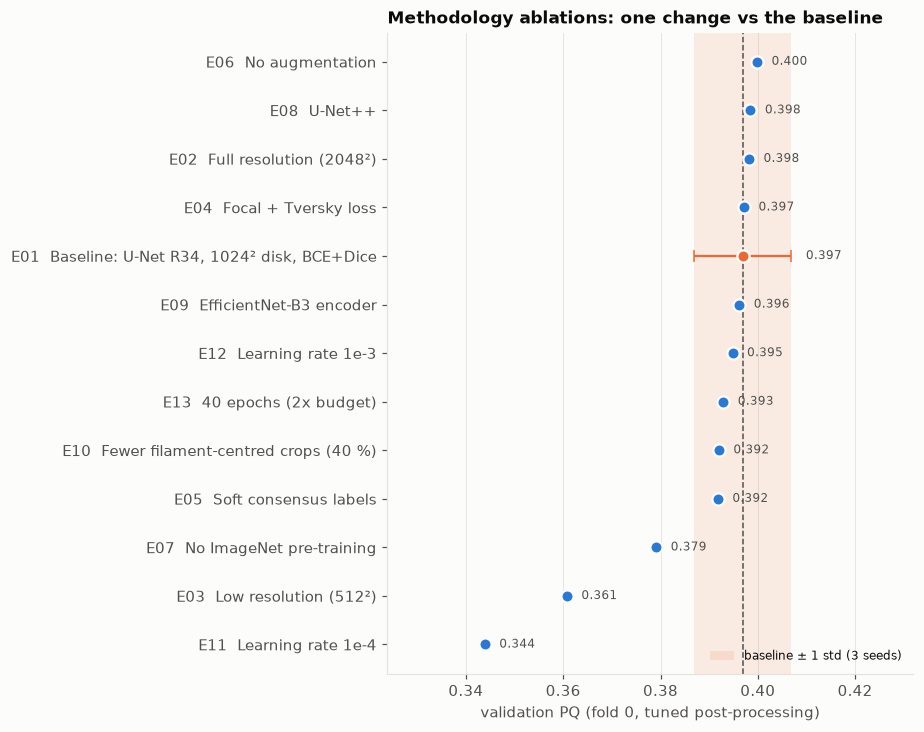

In [38]:
# Dot plot (not bars): the x-axis is truncated, and bars from a non-zero baseline exaggerate gaps.
order = agg.sort_values("pq_tuned_mean").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8.5, 0.42 * len(order) + 1.3))
b = float(order.loc[order.id == "E01", "pq_tuned_mean"].iloc[0])
ax.axvspan(b - NOISE, b + NOISE, color=viz.ACCENT, alpha=0.12, linewidth=0, label="baseline ± 1 std (3 seeds)")
ax.axvline(b, color=viz.TEXT_2, linestyle="--", linewidth=1)
for y, r in order.iterrows():
    col = viz.ACCENT if r.id == "E01" else viz.SEQ
    err = r.pq_tuned_std if r.n_seeds > 1 else 0
    if err:
        ax.errorbar(r.pq_tuned_mean, y, xerr=err, fmt="none", ecolor=col, elinewidth=1.5, capsize=4)
    ax.plot(r.pq_tuned_mean, y, "o", color=col, markersize=8, markeredgecolor=viz.SURFACE, markeredgewidth=1.5)
    ax.text(r.pq_tuned_mean + err + 0.003, y, f"{r.pq_tuned_mean:.3f}", va="center", fontsize=8, color=viz.TEXT_2)
ax.set_yticks(range(len(order)), order.id + "  " + order.change)
ax.set_xlim(max(0, (order.pq_tuned_mean - order.pq_tuned_std.fillna(0)).min() - 0.02),
            (order.pq_tuned_mean + order.pq_tuned_std.fillna(0)).max() + 0.025)
ax.set_xlabel("validation PQ (fold 0, tuned post-processing)")
ax.set_title("Methodology ablations: one change vs the baseline")
ax.legend(loc="lower right", fontsize=8); ax.grid(axis="y", visible=False)
fig.tight_layout(); viz.save(fig, "meth_ablation_pq"); plt.show()

### Post-processing sensitivity (baseline, fold 0)

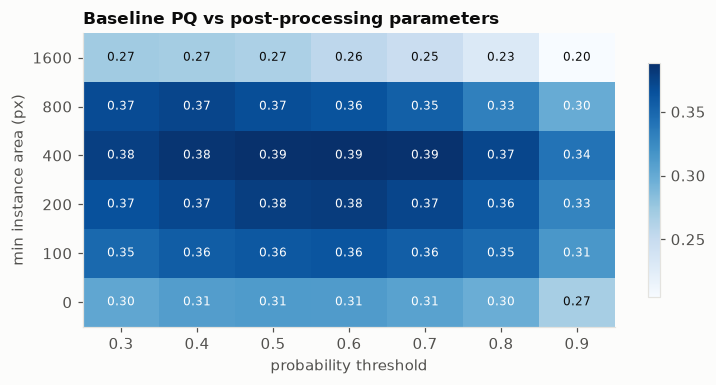

In [39]:
grid = pd.read_csv(Path(RUNS_DIR) / "e01_baseline" / "fold0" / "post_grid.csv").pivot(index="min_area", columns="threshold", values="pq_global")
fig, ax = plt.subplots(figsize=(7, 3.6))
im = ax.imshow(grid.values, cmap="Blues", aspect="auto", origin="lower")
ax.set_xticks(range(grid.shape[1]), [f"{t:.1f}" for t in grid.columns]); ax.set_yticks(range(grid.shape[0]), grid.index)
for (r, c), v in np.ndenumerate(grid.values):
    ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=8,
            color="white" if v > np.nanmax(grid.values) * 0.75 else viz.TEXT)
ax.set_xlabel("probability threshold"); ax.set_ylabel("min instance area (px)"); ax.grid(False)
ax.set_title("Baseline PQ vs post-processing parameters")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout(); viz.save(fig, "meth_post_grid"); plt.show()

**Conclusions of the ablations**
* **Run-to-run noise** (baseline, 3 seeds) is ±0.010 PQ. Nine of twelve changes fall inside it: at
  this budget the network is not the bottleneck.
* **Significant effects**: input resolution (512² loses 0.036 PQ, as predicted by the filament-width
  analysis in 1.2), ImageNet pre-training (+0.018), learning rate (1e-4 under-trains in 20 epochs:
  0.344). Full resolution (E02) brings no gain at 4× the input pixels, so 1024² is kept.
* **Post-processing tuning adds ≈ +0.03 PQ in every run**; a minimum instance area of 400 px is always
  optimal, while the best threshold varies (0.4–0.8) with the loss and calibration.
* **Fragmentation dominates the errors**: one-to-many errors outnumber many-to-one errors 4–5× in
  every run. The next gains come from instance extraction (section 4), not the network.
* **EfficientNet-B3** matches the baseline with 54 % of the parameters (13.2 M, 51 MB vs 93 MB): input
  for the compression work (section 4.4).
* **Decision:** keep the simplest configuration, the E01 baseline, as the final model.

## 2.7 Training curves

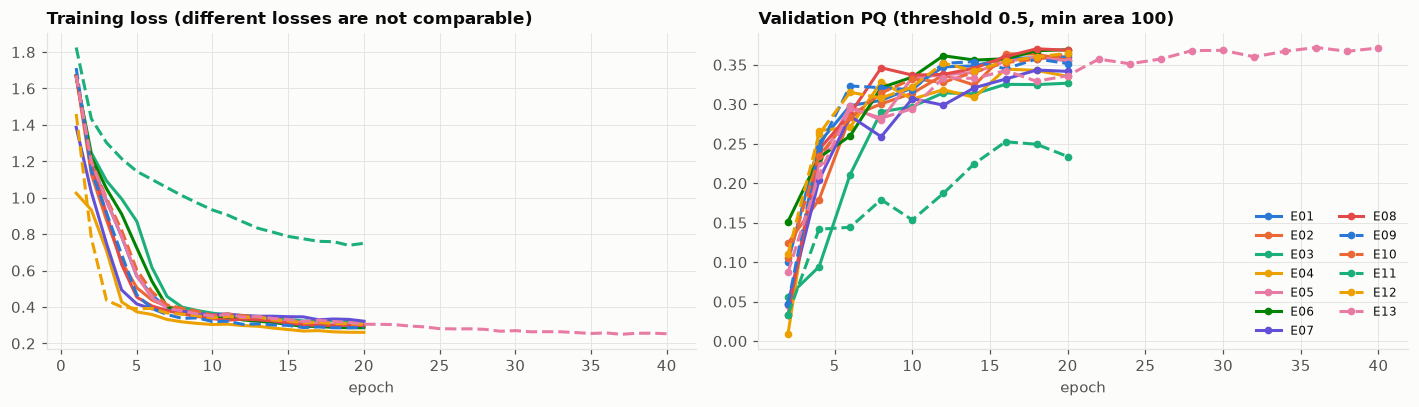

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for i, (eid, h) in enumerate(sorted(hist.items())):
    col = viz.SERIES[i % len(viz.SERIES)]
    ls = "-" if i < len(viz.SERIES) else "--"
    axes[0].plot(h.epoch, h.train_loss, color=col, linestyle=ls, label=eid)
    v = h.dropna(subset=["val_pq_global"])
    axes[1].plot(v.epoch, v.val_pq_global, color=col, linestyle=ls, marker="o", markersize=4, label=eid)
axes[0].set_title("Training loss (different losses are not comparable)"); axes[0].set_xlabel("epoch")
axes[1].set_title("Validation PQ (threshold 0.5, min area 100)"); axes[1].set_xlabel("epoch")
axes[1].legend(ncol=2, fontsize=8)
fig.tight_layout(); viz.save(fig, "meth_learning_curves"); plt.show()

Validation PQ still rises at epoch 20 for most runs, but doubling the budget (E13, 40 epochs) does not
improve the tuned PQ (0.393 vs 0.397 ± 0.010): the 20 × 1000-crop budget is sufficient.

## 2.8 Model size, training time & inference time

In [41]:
res.query("seed == 0")[["id", "change", "params_M", "size_MB", "train_min", "sec_per_img", "device"]].round(2)

,id,change,params_M,size_MB,train_min,sec_per_img,device
0,E01,"Baseline: U-Net R34, 1024² disk, BCE+Dice",24.43,93.36,25.35,0.43,cuda
3,E02,Full resolution (2048²),24.43,93.36,25.81,0.53,cuda
4,E03,Low resolution (512²),24.43,93.36,24.39,0.38,cuda
5,E04,Focal + Tversky loss,24.43,93.36,27.32,0.49,cuda
6,E05,Soft consensus labels,24.43,93.36,30.70,0.49,cuda
7,E06,No augmentation,24.43,93.36,23.85,0.41,cuda
8,E07,No ImageNet pre-training,24.43,93.36,26.00,0.44,cuda
9,E08,U-Net++,26.07,99.66,34.56,0.47,cuda
10,E09,EfficientNet-B3 encoder,13.16,50.75,26.32,0.45,cuda
11,E10,Fewer filament-centred crops (40 %),24.43,93.36,24.00,0.42,cuda


`sec_per_img` = model (whole disk at the input scale, upsampled to 2048²) + post-processing, on the
T4 during validation. Training time is wall-clock for 20 epochs including validation every 2 epochs.

## 2.9 Final configuration: 5-fold cross-validation

The final model (E01 baseline) is trained on **all 5 folds** with the same protocol: one model per
fold, each validated on its held-out fold. This gives (i) mean ± std over 5 independent runs, (ii)
out-of-fold probabilities for all 707 training observations and (iii) 5 models for an ensemble
submission. Post-processing is then tuned **once on the pooled out-of-fold predictions** (sums of
TP/FP/FN/IoU over all folds), which is less optimistic than tuning on each fold.

In [42]:
FINAL = "e01_baseline"
if TRAIN:
    for f in range(5):
        !{train_cmd(FINAL, fold=f)} --out-dir "{RUNS_DIR}"
        !python -m filaments.tune_post "{RUNS_DIR}/{FINAL}/fold{f}" --workers 2 --thresholds 0.3 0.4 0.5 0.6 0.7 0.8 0.9 --min-areas 0 100 200 400 800 1600
# Kaggle equivalent (what was run): kaggle_run.launch("final_a", [], jobs=[(FINAL, COMMON + ["--fold", str(f)]) for f in (1, 2)])

# Pooled post-processing tuning: PQ from TP/FP/FN/IoU summed over the grids of all 5 folds.
grids = []
for f in range(5):
    g = pd.read_csv(Path(RUNS_DIR) / FINAL / f"fold{f}" / "post_grid.csv").assign(fold=f)
    grids.append(g.assign(iou_sum=g.sq * g.tp))
grids = pd.concat(grids)
pool = grids.groupby(["threshold", "min_area"])[["iou_sum", "tp", "fp", "fn", "one_to_many", "many_to_one"]].sum()
pool["pq"] = pool.iou_sum / (pool.tp + 0.5 * pool.fp + 0.5 * pool.fn)
thr, area = pool.pq.idxmax()
POST = {"threshold": float(thr), "min_area": int(area), "pq_global_pooled": float(pool.pq.max())}
(Path(RUNS_DIR) / FINAL / "post_pooled.json").write_text(json.dumps(POST, indent=1))
print("pooled best post-processing:", POST)
pool.pq.unstack("threshold").round(3)

pooled best post-processing: {'threshold': 0.5, 'min_area': 400, 'pq_global_pooled': 0.37832547805467254}


threshold,0.3,0.4,0.5,0.6,0.7,0.8,0.9
min_area,,,,,,,
0,0.296,0.301,0.301,0.299,0.294,0.280,0.252
100,0.342,0.347,0.349,0.348,0.343,0.329,0.299
200,0.358,0.364,0.367,0.366,0.362,0.347,0.315
400,0.372,0.377,0.378,0.378,0.372,0.357,0.327
800,0.355,0.354,0.353,0.348,0.338,0.316,0.287
1600,0.268,0.266,0.260,0.253,0.243,0.226,0.201


In [43]:
final = []
for f in range(5):
    run = Path(RUNS_DIR) / FINAL / f"fold{f}"
    s = json.loads((run / "summary.json").read_text())
    g = grids.query("fold == @f and threshold == @thr and min_area == @area").iloc[0]
    final.append({"fold": f, "pq_default": s["val_pq_global"], "pq_tuned": g.pq_global, "sq": g.sq, "rq": g.rq,
                  "dice": s["val_dice_mean"], "one_to_many": g.one_to_many, "many_to_one": g.many_to_one,
                  "train_min": s["train_sec"] / 60,
                  "sec_per_img": s["val_sec_per_image_model"] + s["val_sec_per_image_post"]})
final = pd.DataFrame(final)
final.to_csv(METH / "final_5fold.csv", index=False)
stats = final.drop(columns="fold").agg(["mean", "std"])
display(final.round(3))
print("\n".join(f"{k:12s} {stats.loc['mean', k]:.3f} ± {stats.loc['std', k]:.3f}" for k in stats.columns))

,fold,pq_default,pq_tuned,sq,rq,dice,one_to_many,many_to_one,train_min,sec_per_img
0,0,0.360,0.387,0.667,0.581,0.675,109.0,19.0,25.351,0.435
1,1,0.354,0.396,0.667,0.593,0.665,100.0,36.0,26.653,0.474
2,2,0.354,0.374,0.664,0.563,0.636,89.0,24.0,25.745,0.447
3,3,0.345,0.366,0.663,0.552,0.663,125.0,41.0,27.019,0.480
4,4,0.333,0.365,0.666,0.548,0.648,131.0,26.0,26.971,0.465


pq_default   0.349 ± 0.010
pq_tuned     0.378 ± 0.014
sq           0.665 ± 0.002
rq           0.568 ± 0.019
dice         0.658 ± 0.016
one_to_many  110.800 ± 17.355
many_to_one  29.200 ± 9.039
train_min    26.348 ± 0.757
sec_per_img  0.460 ± 0.019


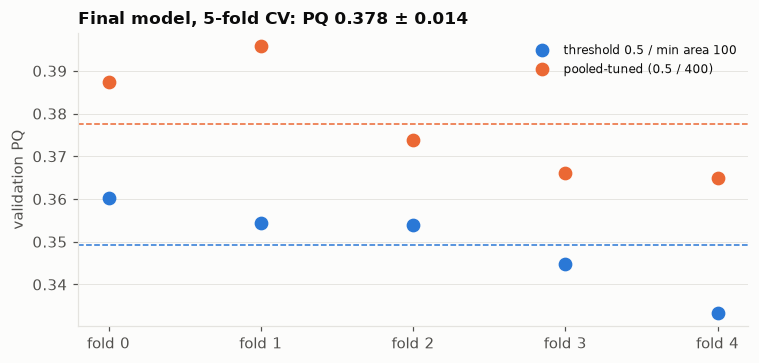

In [44]:
fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(5)
ax.plot(x, final.pq_default, "o", color=viz.SEQ, ms=8, label="threshold 0.5 / min area 100")
ax.plot(x, final.pq_tuned, "o", color=viz.ACCENT, ms=8, label=f"pooled-tuned ({thr:.1f} / {area})")
for col, c in [("pq_default", viz.SEQ), ("pq_tuned", viz.ACCENT)]:
    ax.axhline(final[col].mean(), color=c, linestyle="--", linewidth=1)
ax.set_xticks(x, [f"fold {i}" for i in x]); ax.set_ylabel("validation PQ")
ax.set_title(f"Final model, 5-fold CV: PQ {final.pq_tuned.mean():.3f} ± {final.pq_tuned.std():.3f}")
ax.legend(fontsize=8); ax.grid(axis="x", visible=False)
fig.tight_layout(); viz.save(fig, "meth_final_5fold"); plt.show()

**Final model** (U-Net ResNet-34, 1024² disk, BCE + Dice, full augmentation, AdamW 3e-4, 20 × 1000
crops; threshold 0.5, min area 400): **5-fold PQ 0.378 ± 0.014** (default post-processing
0.349 ± 0.010), Dice 0.658 ± 0.016, 24.4 M parameters / 93 MB, ≈ 26 min training per fold on a T4,
≈ 0.46 s per image (model + post-processing). Folds 0–1 score ≈ 0.39, folds 2–4 0.365–0.374, so
the fold-0 ablation numbers are slightly optimistic in absolute terms (comparisons between
experiments, all on fold 0, are unaffected). The pooled-tuned setting (0.5 / 400) is within 0.001 of each
fold's own optimum, so the post-processing choice is stable across folds. Fragmentation remains the
dominant error (one-to-many 89–131 vs many-to-one 19–41 per fold).

# 3. Segmentation Results

*(Segmentation results owner.)* Report means ± standard deviations over multiple runs (5 folds and/or
seeds), local vs leaderboard, the kinds of errors, and best/worst predictions on test images.

## 3.1 Local PQ (mean ± std over folds / seeds)

In [45]:
# 5-fold results of the final configuration (computed in 2.9, post-processing tuned on pooled OOF)
display(final.round(3)); print(final.drop(columns="fold").agg(["mean", "std"]).round(3))

,fold,pq_default,pq_tuned,sq,rq,dice,one_to_many,many_to_one,train_min,sec_per_img
0,0,0.360,0.387,0.667,0.581,0.675,109.0,19.0,25.351,0.435
1,1,0.354,0.396,0.667,0.593,0.665,100.0,36.0,26.653,0.474
2,2,0.354,0.374,0.664,0.563,0.636,89.0,24.0,25.745,0.447
3,3,0.345,0.366,0.663,0.552,0.663,125.0,41.0,27.019,0.480
4,4,0.333,0.365,0.666,0.548,0.648,131.0,26.0,26.971,0.465


      pq_default  pq_tuned     sq     rq   dice  one_to_many  many_to_one  \
mean       0.349     0.378  0.665  0.568  0.658      110.800       29.200   
std        0.010     0.014  0.002  0.019  0.016       17.355        9.039   

      train_min  sec_per_img  
mean     26.348        0.460  
std       0.757        0.019  


## 3.2 Error analysis

Per site and per error type (FP, FN, one-to-many = fragmentation, many-to-one = over-merging).

In [46]:
# per-site PQ and error types on the validation fold
p = Path(RUNS_DIR) / FINAL / "fold0" / "val_per_image.csv"
if p.exists():
    v = pd.read_csv(p)
    display(v.groupby("site")[["pq", "dice", "fp", "fn", "one_to_many", "many_to_one"]].mean().round(3))

,pq,dice,fp,fn,one_to_many,many_to_one
site,,,,,,
Bh,0.361,0.701,6.562,3.688,1.094,0.219
Ch,0.373,0.683,4.176,3.294,0.735,0.118
Lh,0.351,0.690,4.844,3.178,0.911,0.111
Mh,0.382,0.653,3.611,2.167,0.417,0.028
Th,0.337,0.647,3.375,1.850,0.450,0.025
Uh,0.402,0.677,3.833,1.833,0.333,0.021


## 3.3 Qualitative results: best and worst cases

Ground truth (left) vs prediction (right) for the best and worst validation images; repeat on test
images with `predict.py` outputs (no ground truth).

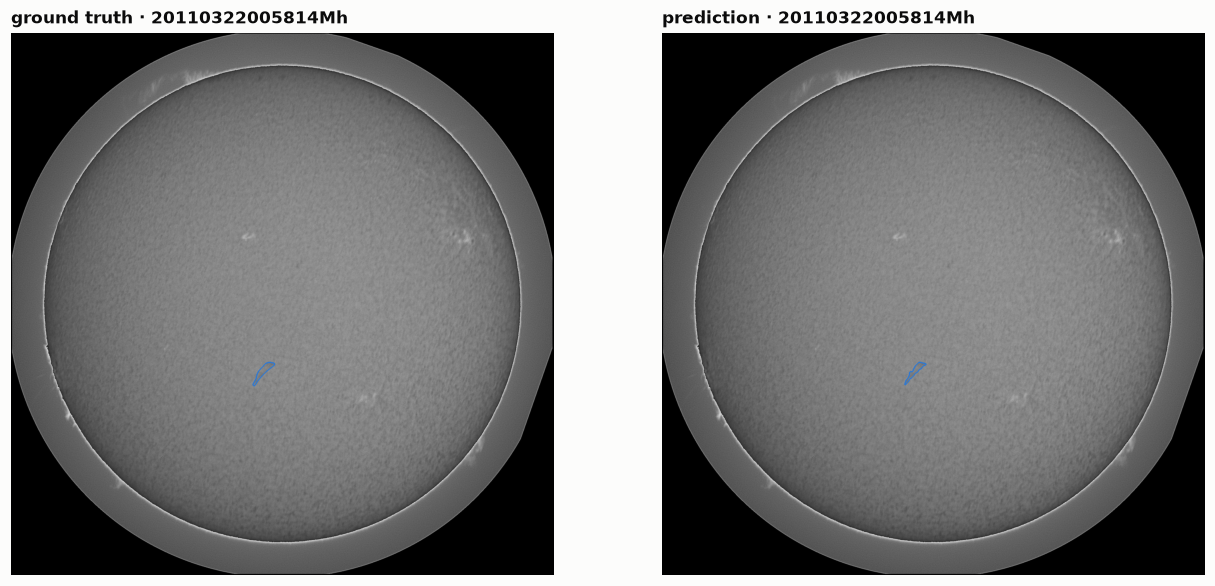

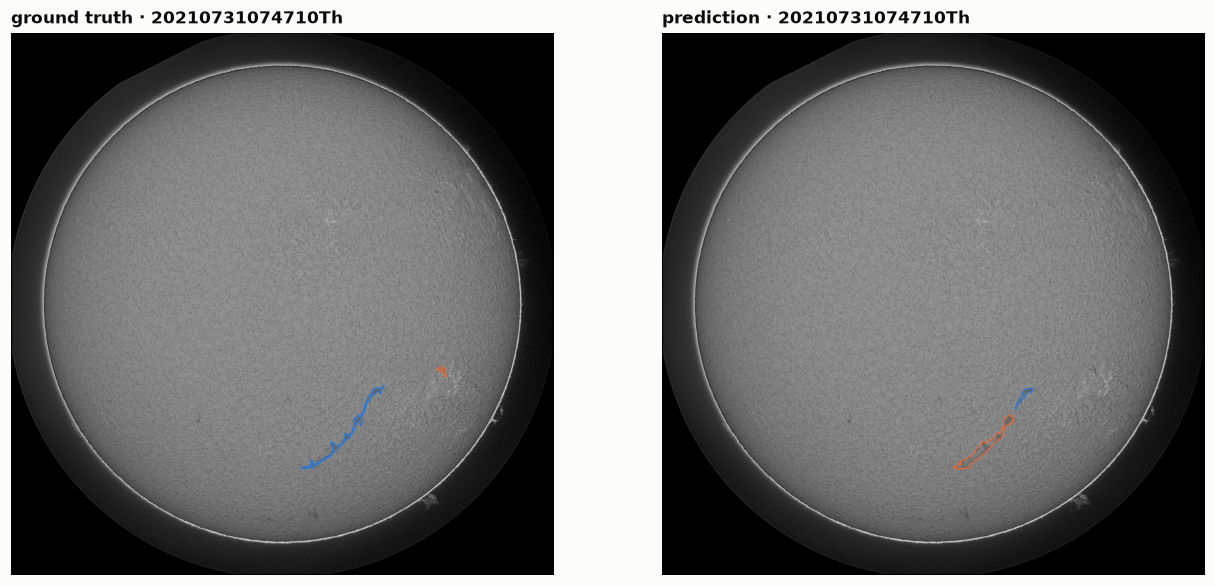

In [47]:
from filaments.evaluate import to_native, polygon_rles
from filaments.postprocess import PostConfig, instances_from_prob
def show_case(run_dir, set_id, post=None, crop=None):
    run_dir = Path(run_dir); s = next(x for x in sets if x.set_id == set_id)
    post = post or PostConfig(**{k: v for k, v in json.loads((run_dir / "post_best.json").read_text()).items()
                                 if k in ("threshold", "min_area")})
    prob = to_native(cv2.imread(str(run_dir / "oof_probs" / f"{s.observation}.png"), 0).astype(np.float32) / 255)
    pred = instances_from_prob(prob, post); img = load_image(image_path(s.observation))
    cols = [viz.hex_to_rgb(c) for c in viz.SERIES]
    gt_ov = A.overlay(img, s.instance_masks(), cols, 4); pr_ov = A.overlay(img, [pred == i for i in np.unique(pred[pred > 0])], cols, 4)
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    for a, im, t in zip(axes, [gt_ov, pr_ov], ["ground truth", "prediction"]):
        a.imshow(im if crop is None else im[crop]); a.set_title(f"{t} · {s.observation}"); a.axis("off")
    plt.show()
p = Path(RUNS_DIR) / FINAL / "fold0"
if (p / "val_per_image.csv").exists():
    v = pd.read_csv(p / "val_per_image.csv").sort_values("pq")
    for sid in [v.set_id.iloc[-1], v.set_id.iloc[0]]:   # best, worst
        show_case(p, sid)

## 3.4 Kaggle leaderboard submission

In [48]:
%%writefile src/filaments/predict.py
"""Predict the test set and write a Kaggle submission (end-to-end timed).

    python -m filaments.predict --ckpts runs/<name>/fold*/best.pt --out submission.csv [--tta]

Several checkpoints (e.g. the 5 fold models) are averaged at the probability level.
Post-processing defaults to the tuned values in <run>/post_best.json of the first checkpoint, if present.
"""
from __future__ import annotations

import argparse
import json
import time
from pathlib import Path

import numpy as np
import torch

from .data import TEST_IMAGES
from .dataset import full_disk_input
from .evaluate import predict_prob, to_native
from .models import build_model, pick_device
from .postprocess import PostConfig, instances_from_prob
from .preprocess import ProfileStore
from .rle import label_map_to_rows, read_submission, write_submission


def load_models(paths, device):
    models, scale = [], None
    for p in paths:
        ckpt = torch.load(p, map_location=device)
        cfg = ckpt["config"]
        m = build_model(cfg["arch"], cfg["encoder"], weights=None).to(device).eval()
        m.load_state_dict(ckpt["model"])
        if scale is not None and cfg["scale"] != scale:
            raise ValueError("all checkpoints must share the same input scale")
        scale = cfg["scale"]
        models.append(m)
    return models, scale


def main(argv=None):
    p = argparse.ArgumentParser(description=__doc__)
    p.add_argument("--ckpts", nargs="+", required=True)
    p.add_argument("--out", default="submission.csv")
    p.add_argument("--tta", action="store_true")
    p.add_argument("--threshold", type=float)
    p.add_argument("--min-area", type=int)
    p.add_argument("--limit", type=int)
    args = p.parse_args(argv)

    t_start = time.perf_counter()
    device = pick_device()
    models, scale = load_models(args.ckpts, device)
    tuned = Path(args.ckpts[0]).parent / "post_best.json"
    post = PostConfig(**{k: v for k, v in json.loads(tuned.read_text()).items() if k in ("threshold", "min_area")}) \
        if tuned.exists() else PostConfig()
    if args.threshold is not None:
        post.threshold = args.threshold
    if args.min_area is not None:
        post.min_area = args.min_area
    amp = device.type == "cuda"

    observations = sorted(p.stem for p in TEST_IMAGES.glob("*.jpeg"))[: args.limit]
    profiles, rows = ProfileStore(), []
    for obs in observations:
        x = full_disk_input(obs, scale, profiles)
        prob = np.mean([predict_prob(m, x, device, tta=args.tta, amp=amp) for m in models], axis=0)
        rows += label_map_to_rows(obs, instances_from_prob(to_native(prob), post))
    write_submission(rows, args.out)
    total = time.perf_counter() - t_start

    check = read_submission(args.out)
    report = {"images": len(observations), "images_with_predictions": len(check), "rows": len(rows),
              "post": vars(post), "tta": args.tta, "n_models": len(models),
              "total_sec": total, "sec_per_image": total / max(len(observations), 1), "device": str(device)}
    Path(args.out).with_suffix(".json").write_text(json.dumps(report, indent=2))
    print(json.dumps(report, indent=2))


if __name__ == "__main__":
    main()

Overwriting src/filaments/predict.py


In [49]:
CKPTS = " ".join(f'"{p}"' for p in sorted(Path(RUNS_DIR).glob(f"{FINAL}/fold*/best.pt")))
!python -m filaments.predict --ckpts {CKPTS} --out submissions/{FINAL}.csv --threshold {POST["threshold"]} --min-area {POST["min_area"]}
# Submit (uses one of 5 daily submissions):
# !kaggle competitions submit -c filament-segmentation-2026 -f submissions/{FINAL}.csv -m "{FINAL}"

{
  "images": 180,
  "images_with_predictions": 177,
  "rows": 1251,
  "post": {
    "threshold": 0.5,
    "min_area": 400
  },
  "tta": false,
  "n_models": 5,
  "total_sec": 87.74024512500182,
  "sec_per_image": 0.4874458062500101,
  "device": "mps"
}


| Submission | Local PQ (fold 0) | Public LB |
|---|---|---|
| E01 baseline, fold-0 model, thr 0.6 / min area 400 | 0.389 | 0.32 |
| E01 baseline, 5-fold ensemble, thr 0.5 / min area 400 | 0.378 ± 0.014 (5-fold CV) | *to submit* |

The local→public gap (≈ 0.07) is also reported by other teams (public notebook *"OOF 0.45 vs Public
0.39"*): methods are compared locally; the leaderboard is used for final confirmation only.

## 3.5 End-to-end inference & timing

`predict.py`: JPEG → disk normalisation (cached profile) → model at 1024² (optionally TTA, several
fold models averaged) → upsample to 2048² → threshold + connected components + min area → COCO RLE
→ `submission.csv`. The whole run is timed, including model loading and file writing.

In [50]:
p = Path(f"submissions/{FINAL}.json")
print(p.read_text() if p.exists() else "run 3.4 first")

{
  "images": 180,
  "images_with_predictions": 177,
  "rows": 1251,
  "post": {
    "threshold": 0.5,
    "min_area": 400
  },
  "tta": false,
  "n_models": 5,
  "total_sec": 87.74024512500182,
  "sec_per_image": 0.4874458062500101,
  "device": "mps"
}


### Model size and timing

Report for the final model (and each compressed variant): parameters, size on disk, training time
and hardware, inference seconds per image (model, post-processing, end-to-end).

In [51]:
res[["run", "params_M", "size_MB", "train_min", "sec_per_img"]].round(3)

,run,params_M,size_MB,train_min,sec_per_img
0,e01_baseline,24.430,93.359,25.351,0.435
1,e01_baseline_s1,24.430,93.359,27.648,0.479
2,e01_baseline_s2,24.430,93.359,27.060,0.507
3,e02_scale1,24.430,93.359,25.815,0.528
4,e03_scale025,24.430,93.359,24.392,0.378
5,e04_focal_tversky,24.430,93.359,27.316,0.486
6,e05_soft,24.430,93.359,30.705,0.493
7,e06_noaug,24.430,93.359,23.855,0.410
8,e07_scratch,24.430,93.359,26.004,0.436
9,e08_unetpp,26.072,99.657,34.562,0.468


# 4. Segmentation Enhancements

*(Segmentation enhancement owner.)* Every idea is measured against the same baseline on the same
out-of-fold probabilities, and reported as a PQ gain (+ cost). The baseline's errors are dominated by
**fragmentation** (one filament → several pieces: ≈ 5× more one-to-many than many-to-one errors).

## 4.1 Instance separation

In [52]:
# e.g. boundary/distance-map head + watershed; compare many_to_one before/after

## 4.2 Post-processing

In [53]:
# Starting point: baseline post-processing = threshold + connected components + min area
# (filaments.postprocess.instances_from_prob). Ideas: merge fragments closer than d px along a common
# direction, hysteresis thresholding, morphological closing, hole filling. Tune on
# RUNS_DIR/<run>/fold0/oof_probs with the same scoring as tune_post (no retraining needed).

## 4.3 Fine-scale structure recovery

In [54]:
# e.g. full-resolution model (E02), clDice loss (--loss bce:1,dice:1,cldice:0.5), TTA (predict --tta)

## 4.4 Compression / distillation / pruning

Available hooks: `count_params`, `size_mb` (2.2);
`--arch/--encoder` for a smaller student (e.g. `resnet18`, `mobilenet_v2`); out-of-fold
probabilities of the teacher in `runs/<run>/fold*/oof_probs/` as soft targets; `predict.py` times
end-to-end inference.

In [55]:
# e.g. distil into resnet18 / mobilenet student, prune, FP16/INT8; report size_mb, params and seconds per image

# 5. Conclusions & Bibliography

* **Main take-aways:** *(fill in from sections 2–4)*
* **Biggest roadblocks:** off-limb halo misleading disk detection; annotator disagreement on instance
  granularity (expert PQ ≈ 0.34); local → leaderboard gap; Kaggle GPU limits (2 concurrent sessions).
* **What we would do differently:** *(fill in)*

## Bibliography

1. A. Ahmadzadeh et al. MAGFiLO: Manually Annotated GONG Filaments from H-Alpha Observations. *Scientific Data* 11:1031, 2024.
2. A. Kirillov, K. He, R. Girshick, C. Rother, P. Dollár. Panoptic Segmentation. *CVPR* 2019.
3. O. Ronneberger, P. Fischer, T. Brox. U-Net: Convolutional Networks for Biomedical Image Segmentation. *MICCAI* 2015.
4. K. He, X. Zhang, S. Ren, J. Sun. Deep Residual Learning for Image Recognition. *CVPR* 2016.
5. Z. Zhou et al. UNet++: A Nested U-Net Architecture for Medical Image Segmentation. *DLMIA* 2018.
6. M. Tan, Q. Le. EfficientNet: Rethinking Model Scaling for CNNs. *ICML* 2019.
7. T.-Y. Lin et al. Focal Loss for Dense Object Detection. *ICCV* 2017.
8. S. S. M. Salehi et al. Tversky Loss Function for Image Segmentation. *MLMI* 2017.
9. S. Shit et al. clDice — a Novel Topology-Preserving Loss Function for Tubular Structure Segmentation. *CVPR* 2021.
10. I. Loshchilov, F. Hutter. Decoupled Weight Decay Regularization (AdamW). *ICLR* 2019.
11. P. Iakubovskii. Segmentation Models PyTorch. GitHub, 2019.